# 01 · Exploratory data analysis: which new Kindle books become popular?

**Project:** Digital Publishing Opportunity Intelligence

**Author:** Stefan Radević · Data Science Bootcamp · Capstone project

## 1. TL;DR

**Key findings**

- I started with **1,591,371** Kindle books, kept the **438,830** published in 2019–2022, took a random sample of **200,000** and ended with **176,367** clean books.
- **Experience matters most:** 61% of books by authors with 10+ earlier books reach 100 ratings, but only 16% of first books.
- **Series** (49% against 29%) and **publishers** (50% against 28% for self-published books) also help.
- **Romance** (50%) and **Mystery, Thriller & Suspense** (46%) are the strongest niches; practical non-fiction such as Education, Self-Help, Computers and Business (12–15%) the weakest.
- A price of 0 usually means **Kindle Unlimited**, not a free book.

**My target.** A book is **popular** if it gets at least **100 estimated ratings in its first 12 months**. This was the only tested threshold that passed all my
rules: **32.4%** of the books reach it, and they hold **94.4%** of first-year ratings.

**Income is only an estimate here.** The data has no copies sold. With 50 buyers per rating, the median self-published book would earn about **920 dollars a
year** (368 with 20, 1,840 with 100), and income falls fast with age: **26.7%** of the first year's income in year 2 and **14.1%** in year 3.

## 2. Introduction & motivation

Many people want to publish e-books on Amazon Kindle, and before they start they would like to know which books find readers.
Amazon does not publish the number of copies sold, so this project studies **popularity** through the number of ratings. It asks:

> **Can we predict, from the characteristics of a book draft, whether a new Kindle book will reach at least 100 ratings in its
> first 12 months on Amazon?**

- **Ratings** are the star ratings readers give a book. I use **how many** there are, not how many stars they give.
- **Popular** means at least 100 estimated ratings in the first 12 months. Section 9.18 shows how I chose this number.
- **Characteristics of a draft** are the niche, the length, the title length and whether the book is part of a series. I also use two
  facts about how it is published: self-published or with a publisher, and how many books the author has published before.
- The result is a **probability** of reaching the threshold, together with the characteristics linked with a higher chance.

This notebook looks at the data, cleans it, chooses the definition of popularity and prepares one table for the models. The
models are in the `02.x` notebooks. Sections 9.6–9.16 also explore price and a possible income, which are context and not part of the
prediction target.

## 3. Data provenance

| | |
|---|---|
| **Source** | Amazon Reviews 2023, Kindle Store **metadata**: [amazon-reviews-2023.github.io](https://amazon-reviews-2023.github.io/) (McAuley Lab, UC San Diego; Hou et al., 2024) |
| **File** | `data/raw/meta_Kindle_Store.jsonl`: one line per book, 6.9 GB |
| **Period** | books on Amazon until September 2023; `rating_number` was collected in 2023 |
| **Downloaded** | January 2025 |
| **Terms** | released for research; I use it for education only and cite the paper |

The original file is never changed. Everything else, from reading the file to the sample and the clean table, is done
step by step in this notebook.

**Used only for checks and rules**

| Source | Use |
|---|---|
| [Kaggle: Amazon Kindle Books Dataset 2023](https://www.kaggle.com/datasets/asaniczka/amazon-kindle-books-dataset-2023-130k-books) (`data/raw/kindle_data-v2.csv`) | Kindle Unlimited and Best Seller labels (7.2, 9.6, 9.13) |
| Amazon Reviews 2023, `data/raw/Kindle_Store_0core.csv` | dates of reviews (9.9, 9.11) |
| [KDP help pages](https://kdp.amazon.com/en_US/help/topic/G200644210) and [Authors Guild](https://authorsguild.org/news/e-book-royalty-math-the-house-always-wins-2/) | royalty rules (9.7) |

## 4. Data dictionary

**Columns I take from the original file**

| Column | Meaning | Units / values |
|---|---|---|
| `parent_asin` | book ID | text |
| `title` | book title | text |
| `author` → `author_name` | the author's name (inside the `author` field) | text |
| `store` | contributors and format; names the author when `author_name` is empty | text |
| `categories` | Amazon category path; the 3rd level is the niche | list, e.g. `["Kindle Store", "Kindle eBooks", "Romance"]` |
| `price` | price in 2023 | dollars, sometimes text (`"—"`, `"from 2.99"`) |
| `rating_number` | total number of star ratings on Amazon in 2023 | count |
| `details` → `publisher` | publisher and date | text, e.g. `"Berkley (June 2, 2020)"` |
| `details` → `publication_date` | date of publication | text, e.g. `"May 25, 2021"` |
| `details` → `print_length` | length of the book | text, e.g. `"378 pages"` |

**Columns I create**

| Column | Meaning | Units / values |
|---|---|---|
| `niche` | the book's genre | 30 niches in the sample |
| `price`, `pages` | price and length as numbers | dollars; pages |
| `publication_year` | year of publication | 2019–2022 |
| `self_published` | 1 if the book has no publisher, a self-publishing service, or the author's own small imprint | 0 / 1 |
| `is_series` | 1 if the title shows a series ("Book 2", "Series", "#3") | 0 / 1 |
| `title_words` | number of words in the title | count |
| `author_earlier_books` | how many books the same author published before this one | count |
| `popular` | first working target: 1 if the book has at least 100 ratings in total | 0 / 1 |
| `price_known` | True if the price is above 0 | True / False |
| `file_mb` | size of the book file | MB |
| `author_per_copy`, `author_pct` | the author's estimated income from one copy, and as a share of the price | dollars; % |
| `ratings_per_year` | `rating_number` ÷ years on Amazon | ratings a year |
| `reviews_in_file`, `ratings_per_review` | dated reviews of the book in the 0-core file, and Amazon ratings per such review | count; ratio |
| `ratings_to_2022`, `full_year` | estimated ratings up to 31 December 2022; True if the book had at least one full year by then | count; True / False |
| `rating_group` | groups by `ratings_to_2022`: under 20, 20-49, 50-99, 100+ | text |
| `first_year_reviews`, `first_year_ratings` | reviews in the first 12 months, and the estimated ratings in that time | count |
| `popular_first_year` | **final target**: 1 if `first_year_ratings` is at least 100 | 0 / 1 |
| `yearly_income` | **estimate up to 2022**: ratings per year × 50 buyers per rating × `author_per_copy` | dollars a year |

## 5. Setup

### 5.1 Libraries and folders

- `polars` reads very large files quickly and can work on them **without loading everything into memory**. The instructor
  suggested Polars for files of this size.
- `pandas` works with the smaller sample; `matplotlib` and `seaborn` draw the charts.
- `PROJECT` is the project folder, so that the paths to the data work both in VS Code (the notebook runs from
  `notebooks/`) and on GitHub / Colab (it runs from the project folder).
- The three settings of the whole analysis are at the end of the cell: the **period** (books published 2019–2022), the
  **size of the random sample** (200,000 books) and the **seed** that makes the sample the same every time.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import seaborn as sns

# The project folder: one level up when the notebook runs from notebooks/ (VS Code),
# the current folder when it runs from the project folder (GitHub / Colab, as in the course template)
PROJECT = Path("..") if Path.cwd().name == "notebooks" else Path(".")
RAW_FILE = PROJECT / "data" / "raw" / "meta_Kindle_Store.jsonl"
CLEAN = PROJECT / "data" / "clean"
PROCESSED = PROJECT / "data" / "processed"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#c3c2b7"
RANDOM_STATE = 42                 # the same random sample every time the notebook runs
YEAR_FROM, YEAR_TO = 2019, 2022   # the period I analyse: books published in these years
SAMPLE_SIZE = 200_000             # number of books in the random sample
print("Original file:", RAW_FILE.relative_to(PROJECT), f"({RAW_FILE.stat().st_size / 1e9:.1f} GB)")
print(f"Period: books published {YEAR_FROM}-{YEAR_TO} | random sample: {SAMPLE_SIZE:,} books")

Original file: data\raw\meta_Kindle_Store.jsonl (6.9 GB)
Period: books published 2019-2022 | random sample: 200,000 books


### 5.2 Opening the original file with Polars

The original file has 6.9 GB, too much for pandas. **Polars** in *lazy* mode (`scan_ndjson`) does not load the file: it
only prepares the work, and reads the file when a result is asked for.

- `infer_schema_length=None` tells Polars to look at all rows before deciding the column types, because some fields are
  a number in one row and text in another.
- `.collect_schema()` lists the columns and their types, like `.info()` in pandas.
- `.head(3).collect()` reads only the first 3 books.

In [2]:
raw = pl.scan_ndjson(RAW_FILE, infer_schema_length=None)

schema = raw.collect_schema()
print(f"Columns: {len(schema)}")
for name, dtype in schema.items():
    print(f"  {name:16} {str(dtype)[:90]}")

Columns: 16
  main_category    String
  title            String
  subtitle         String
  author           Struct({'avatar': String, 'name': String, 'about': List(String)})
  average_rating   Float64
  rating_number    Int64
  features         List(String)
  description      List(String)
  price            String
  images           List(Struct({'thumb': String, 'large': String, 'variant': String, 'hi_res': String}))
  videos           List(Struct({'title': String, 'url': String, 'user_id': String}))
  store            String
  categories       List(String)
  details          Struct({'Publisher': String, 'Publication date': String, 'Language': String, 'File size': 
  parent_asin      String
  bought_together  Null


In [3]:
raw.head(3).collect()

main_category,title,subtitle,author,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together
str,str,str,struct[3],f64,i64,list[str],list[str],str,list[struct[4]],list[struct[3]],str,list[str],struct[34],str,null
"""Buy a Kindle""","""The Palace (Chateau Book 4)""","""Kindle Edition""","{""https://m.media-amazon.com/images/S/amzn-author-media-prod/4r09vpfv39tvipjnol841nbss8._SY600_.jpg"",""Penelope Sky"",[""A New York Times and USA Today Bestselling Author, Penelope Sky is known for her dark romance that makes you fall for her characters....no matter how dark they seem. Her books are being translated into several languages around the world, and she's sold more than a million books worldwide. She lives in a small town in California with her husband, where she spends most of her time writing on the back porch.""]}",4.7,970,"[""A line was drawn in the sand.I made my choice.I picked her over him.But I begin to regret that choice, and when Raven wants to destroy the camp, I know I'll regret it even more.""]",[],"""0""","[{null,""https://m.media-amazon.com/images/I/51kanedQWFS.jpg"",""MAIN"",null}]",[],"""Penelope Sky (Author) Format…","[""Kindle Store"", ""Kindle eBooks"", ""Romance""]","{""Hartwick Publishing (May 25, 2021)"",""May 25, 2021"",""English"",""2076 KB"",null,""Enabled"",""Supported"",""Enabled"",""Enabled"",""Enabled"",""On Kindle Scribe"",""378 pages"",null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null}","""B08XPZPFY4""",null
"""Buy a Kindle""","""Microsoft PowerPoint 2016 2013…","""[Print Replica] Kindle Edition""","{""https://m.media-amazon.com/images/S/amzn-author-media-prod/4ggqos2hf6db3ukd1p59ifr1ht._SY600_.jpg"",""Amelia Griggs"",[""Amelia Griggs is the author of over a dozen books in 3 different genres including non-fiction technology, children's books, coloring and activity books, and a new series to help other authors learn more about the writing, publishing, and marketing process of being an author. Amelia is also a freelance Instructional Designer and eLearning developer. She enjoys researching, designing and developing all kinds of educational materials, writing instructional articles, blogging, and composing fictional short stories. She is currently working on educational books, how-to guides, and instructional YouTube videos. Amelia has always loved writing for as long as she could remember. She also loves writing short stories, rhymes, and poems, and who knows...there might even be a novel in her future."", ""She has a Bachelor of Business Administration with a Major in Computer Science and a Master of Science in Instructional Design and Technology."", … ""Happiness is doing what you love!""]}",4.3,35,"[""Paperback versions are also available, including Color and NEW LARGE PRINT B&W Version! For 8 X 10 Large Print B&W Recommended Format, go directly to this link: http://a.co/b39NamfFor 7 X 10 Color Paperback, go directly to this link: http://a.co/7i5fBy1"", ""DESCRIPTION:"", … ""*Part I. PowerPoint Basics: Creating a Simple Presentation, PowerPoint Templates, Simple and Fast Formatting, Copy/Paste Tricks, Format Painter, Opening, Saving, Closing and Printing*Part II. Working with the Slide Master*Part III. Working with Slides: Inserting, Deleting, Copying and Moving Slides*Part IV. Backgrounds, Objects, Images and Media*Part V. Slide Show Options: Electronic Pen, Laser Pointer, Highlighter and Presenter View*Part VI. Animation Station and Special Effects*Part VII. Extras: Speaker Notes, Handouts, Hyperlinks, File Conversion, Plus BONUS Tricks to Make You an PowerPoint Expert""]","[""From the Author"", ""Amelia Griggs is an Instructional Designer and eLearning developer. She has a M.S. in Instructional Design and Technology from Philadelphia University, and a B.B.A in Computer Science from Temple University. In addition to designing and developing all kinds of educational material

In [4]:
total_books = raw.select(pl.len()).collect().item()
print(f"Books in the original file: {total_books:,}")

Books in the original file: 1,591,371


- The original file has **1,591,371 books** and **16 columns**.
- Several columns are not simple values: `author` is a small dictionary (picture, name, biography), `categories` a list,
  and `details` a dictionary with publisher, publication date, length and other technical fields.
- `rating_number` is the number of star ratings on Amazon, the basis of my target. `average_rating` is the average of the
  same ratings.

### 5.3 Taking the columns and fields I need

**Where the fields are.** Most columns hold one simple value (a title, a number). Two columns are different: `author`
and `details` are small **dictionaries**, each with several fields inside. The publisher, the publication date and the
length of a book are not separate columns in the original file: they are hidden **inside `details`**. I look at one book
first.

- `.head(1).collect().to_dicts()[0]` reads the first book and turns it into a normal Python dictionary.

In [5]:
first_book = raw.head(1).collect().to_dicts()[0]

print("author:")
for field, value in first_book["author"].items():
    print(f"   {field:12} {str(value)[:70]}")

print("\ndetails (only the fields this book has):")
for field, value in first_book["details"].items():
    if value is not None:
        print(f"   {field:28} {value}")

author:
   avatar       https://m.media-amazon.com/images/S/amzn-author-media-prod/4r09vpfv39t
   name         Penelope Sky
   about        ["A New York Times and USA Today Bestselling Author, Penelope Sky is k

details (only the fields this book has):
   Publisher                    Hartwick Publishing (May 25, 2021)
   Publication date             May 25, 2021
   Language                     English
   File size                    2076 KB
   Text to Speech               Enabled
   Screen Reader                Supported
   Enhanced typesetting         Enabled
   X Ray                        Enabled
   Word Wise                    Enabled
   Sticky notes                 On Kindle Scribe
   Print length                 378 pages


`author` has 3 fields (a picture link, the name and a biography) and `details` has many fields, most of them technical
(file size, text-to-speech, X-Ray, Word Wise…). To decide which fields are worth keeping, I count how many books of the
whole file have each `details` field.

- `.struct.unnest()` opens the dictionary, so that each field becomes its own column; `.count()` counts the filled values.

In [6]:
details_filled = raw.select(pl.col("details").struct.unnest()).count().collect().to_pandas().T[0]
details_filled = (details_filled / total_books * 100).round(1).sort_values(ascending=False)
print("Share of books that have each 'details' field (%):")
details_filled.head(15)

Share of books that have each 'details' field (%):


Language                     96.4
Publication date             96.3
Word Wise                    94.7
File size                    94.7
Text to Speech               94.7
Enhanced typesetting         94.7
Sticky notes                 94.7
Print length                 93.3
X Ray                        91.8
Screen Reader                86.6
Publisher                    62.5
Simultaneous device usage    39.2
Page numbers source ISBN     16.1
Date First Available          1.6
File Size                     1.6
Name: 0, dtype: float64

- The **publication date** (96%) and the **print length** (93%) are filled for almost every book, so they are useful.
- The **publisher** is filled for only 62.5% of the books. The missing publisher is itself information: self-published
  books often have none (7.6).
- The technical fields (Word Wise, file size, text-to-speech…) are also filled for about 95% of the books, but they are
  Kindle settings that are almost the same for every book, not a decision about the book.
- `Language` is filled for 96%, but almost every book is in English, so it does not separate the books.

**Rule.** I keep only what helps the question, and take the useful fields out of the two dictionaries:

| Kept | Where it is | Why |
|---|---|---|
| `parent_asin`, `title` | own columns | book ID; series and title length come from the title |
| `author_name` | inside `author` (field `name`) | the author's earlier books |
| `store` | own column | names the author when `author_name` is empty |
| `categories` | own column | the niche |
| `price` | own column | a decision of the author |
| `rating_number` | own column | the target |
| `publisher` | inside `details` (field `Publisher`) | self-published or publisher |
| `publication_date` | inside `details` (field `Publication date`) | the period 2019–2022 and the year |
| `print_length` | inside `details` (field `Print length`) | the length of the book |

| Removed | Why |
|---|---|
| `author` → `avatar`, `about` | a picture link and a biography, not needed |
| `details` → `Language` | almost every book is in English |
| `details` → file size, text-to-speech, X-Ray, Word Wise, sticky notes and the other fields | technical Kindle settings, not a decision about the book |
| `average_rating` | measured together with the target, it would reveal the answer |
| `main_category`, `subtitle` | almost always "Buy a Kindle" and "Kindle Edition" |
| `features`, `description`, `images`, `videos`, `bought_together` | long texts and media, not needed for this question (`bought_together` is empty) |

**How.** Polars is not part of the course; I use it, as my mentors suggested, because the file has 6.9 GB and pandas
cannot open it. The Polars commands do the same as simple pandas commands:

- `pl.col("details").struct.field("Publisher")` takes one field out of the dictionary, like `details["Publisher"]`;
- `.alias("publisher")` gives the new column its name, like `rename`;
- `.cast(pl.String)` keeps every price as text (some prices are numbers, some are text like `"from 2.99"`); I clean them in
  7.2;
- `.collect(engine="streaming")` finally reads the file, piece by piece, so the memory stays low.

In [7]:
catalog = raw.select(
    "parent_asin",                                                                       # own columns
    "title",
    pl.col("author").struct.field("name").alias("author_name"),                          # from inside "author"
    "store",
    "categories",
    pl.col("price").cast(pl.String).alias("price"),
    "rating_number",
    pl.col("details").struct.field("Publisher").alias("publisher"),                      # from inside "details"
    pl.col("details").struct.field("Publication date").alias("publication_date"),
    pl.col("details").struct.field("Print length").alias("print_length"),
).collect(engine="streaming")

print("All books, selected columns:", catalog.shape, f"| memory: {catalog.estimated_size('mb'):.0f} MB")

All books, selected columns: (1591371, 10) | memory: 366 MB


**Before and after** for the same first book: the fields that were hidden inside `author` and `details` are now simple
columns.

In [8]:
catalog.head(1).to_pandas().T.rename(columns={0: "first book"})

,first book
parent_asin,B08XPZPFY4
title,The Palace (Chateau Book 4)
author_name,Penelope Sky
store,Penelope Sky (Author) Format: Kindle Edition
categories,"[Kindle Store, Kindle eBooks, Romance]"
price,0
rating_number,970
publisher,"Hartwick Publishing (May 25, 2021)"
publication_date,"May 25, 2021"
print_length,378 pages


Now I count the **missing values** in every selected column, as a number and as a share of all books.

- `.null_count()` counts the empty cells of each column; dividing by the number of books gives the percentage.

In [9]:
missing = catalog.null_count().to_pandas().T.rename(columns={0: "missing"})
missing["missing_%"] = (missing["missing"] / len(catalog) * 100).round(1)
missing

,missing,missing_%
parent_asin,0,0.0
title,0,0.0
author_name,335913,21.1
store,11,0.0
categories,0,0.0
price,215559,13.5
rating_number,0,0.0
publisher,596878,37.5
publication_date,58595,3.7
print_length,106157,6.7


- All 1,591,371 books now have **10 simple columns** and take only about **366 MB** in memory.
- Missing values in the whole file: author name for 335,913 books (21.1%), publisher for 596,878 (37.5%), publication
  date for 58,595 (3.7%) and print length for 106,157 (6.7%). Every book has an ID, a title and a number of ratings (0
  missing).

### 5.4 Choosing the books and taking a sample

I keep only books **published from 2019 to 2022** (`YEAR_FROM`, `YEAR_TO`):

- from 2019, so that the books are recent and show today's market;
- until 2022, so that every book had at least about 9 months on Amazon before the ratings were counted in 2023.

Then I take a **random sample of 200,000 books** (`SAMPLE_SIZE`, `seed=42`, the same sample every time). This is almost
half of all books from the period, which is a large random sample: it represents the whole period well, has enough
books in every niche to compare self-published and publisher books, and keeps the later steps fast. I save the sample
as a Parquet file (a compact table format), so that the rest of the notebook can start from it.

- `.str.to_date()` turns text like `"May 25, 2021"` into a date; `strict=False` leaves dates it cannot read empty.
- `.sample(n, seed)` draws a random sample; `.write_parquet()` saves it.

In [10]:
catalog = catalog.with_columns(pl.col("publication_date").str.to_date("%B %d, %Y", strict=False).alias("published"))
print(f"Books without a readable publication date: {catalog['published'].null_count():,}")

recent = catalog.filter(pl.col("published").dt.year().is_between(YEAR_FROM, YEAR_TO))
print(f"Books published {YEAR_FROM}-{YEAR_TO}: {len(recent):,}")

sample = recent.sample(n=SAMPLE_SIZE, seed=RANDOM_STATE)
print(f"Random sample: {len(sample):,} books = {len(sample) / len(recent):.1%} of all books from {YEAR_FROM}-{YEAR_TO}"
      f" ({len(sample) / len(catalog):.1%} of the whole file)")
SAMPLE_FILE = CLEAN / f"kindle_sample_{YEAR_FROM}_{YEAR_TO}.parquet"
sample.write_parquet(SAMPLE_FILE)
print("Saved:", SAMPLE_FILE.relative_to(PROJECT), sample.shape)

Books without a readable publication date: 58,595


Books published 2019-2022: 438,830
Random sample: 200,000 books = 45.6% of all books from 2019-2022 (12.6% of the whole file)


Saved: data\clean\kindle_sample_2019_2022.parquet (200000, 11)


- 58,595 books have no readable publication date, so they cannot be placed in time.
- **438,830 books** were published in 2019–2022.
- The random sample of **200,000 books** is **45.6%** of all books from this period (12.6% of the whole file). Such a
  large random sample represents the period very well.

## 6. First look

From here on I work with the sample in pandas. I load the file I just saved and look at it with `.head()`, `.info()`
and `.describe()`.

In [11]:
books = pd.read_parquet(SAMPLE_FILE)
books.head()

,parent_asin,title,author_name,store,categories,price,rating_number,publisher,publication_date,print_length,published
0,B07NDWT66X,51 Inspirational Sweet Western Romances Box Set: Mail Or...,Katie Wyatt,"Katie Wyatt (Author), Kat Carson (Author), Brenda Clem...","[Kindle Store, Kindle Unlimited, Religion & Spirituality]",0,405,"Royce Cardiff Publishing House; 2nd edition (February 5,...","February 5, 2019",2845 pages,2019-02-05
1,B08NRPBGGR,Back To You,NaN,Steve Bates (Author) Format: Kindle Edition,"[Kindle Store, Kindle eBooks, Literature & Fiction]",6.99,38,"White Bird Publications, LLC; 1st edition (January 5, 2021)","January 5, 2021",254 pages,2021-01-05
2,B09L6VDZTF,The Senders of Fate: Warrior of the Dark Book 2,Garnet Hart,Garnet Hart (Author) Format: Kindle Edition,"[Kindle Store, Kindle eBooks, Literature & Fiction]",0,3,NaN,"November 11, 2021",312 pages,2021-11-11
3,B07ZXPNJLL,Steele's War: A Damascus Steele novel (The Glory Game Bo...,Dietmar Wehr,Dietmar Wehr (Author) Format: Kindle Edition,"[Kindle Store, Kindle eBooks, Science Fiction & Fantasy]",3.99,97,"Non-Linear Visions Inc.; 1st edition (November 2, 2019)","November 2, 2019",365 pages,2019-11-02
4,B07ZN8GD32,Plans I Have for You (Jeremiah 29:11 Book 1),The Noble Sisters,The Noble Sisters (Author) Format: Kindle Edition,"[Kindle Store, Kindle eBooks, Religion & Spirituality]",0,5,NaN,"November 16, 2019",261 pages,2019-11-16


In [12]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   parent_asin       200000 non-null  str   
 1   title             200000 non-null  str   
 2   author_name       175062 non-null  str   
 3   store             199999 non-null  str   
 4   categories        200000 non-null  object
 5   price             177780 non-null  str   
 6   rating_number     200000 non-null  int64 
 7   publisher         105571 non-null  str   
 8   publication_date  200000 non-null  str   
 9   print_length      191610 non-null  str   
 10  published         200000 non-null  object
dtypes: int64(1), object(2), str(8)
memory usage: 51.0+ MB


In [13]:
books.drop(columns=["categories"]).describe(include="all").T[["count", "unique", "top", "min", "50%", "max"]]

,count,unique,top,min,50%,max
parent_asin,200000,200000,B07NDWT66X,NaN,NaN,NaN
title,200000,198678,Second Chances,NaN,NaN,NaN
author_name,175062,88568,Michael Anderle,NaN,NaN,NaN
store,199999,123529,Charles River Editors (Author) Format: Kindle Edition,NaN,NaN,NaN
price,177780,2085,0,NaN,NaN,NaN
rating_number,200000.0,NaN,NaN,1.0,46.0,283149.0
publisher,105571,97415,"Speedy Publishing Books (November 22, 2019)",NaN,NaN,NaN
publication_date,200000,1461,"December 1, 2020",NaN,NaN,NaN
print_length,191610,1974,32 pages,NaN,NaN,NaN
published,200000,1461,2020-12-01,NaN,NaN,NaN


- The sample has **200,000 rows** and **11 columns**, and uses about 51 MB of memory.
- `price`, `print_length` and `publication_date` are **text**, not numbers or dates, so they must be converted.
- `author_name` (175,062 values), `price` (177,780), `publisher` (105,571) and `print_length` (191,610) have empty cells.
- `rating_number` goes from **1** to **283,149** ratings, with a median of **46**: most books have few ratings and a few
  have very many.
- The most frequent author name is *Michael Anderle*, and the most frequent `store` value is *Charles River Editors*
  (a company that publishes short history books). The most frequent price is **0**; section 7.2 checks what this
  means.

## 7. Data quality audit

I check the sample for missing values, duplicates and wrong types, and fix them one by one. The original file is never
changed; every fix happens only in this notebook.

### 7.1 Missing values and duplicates

In [14]:
missing = (books.isna().mean() * 100).round(1).sort_values(ascending=False)
print("Missing values (%):")
print(missing[missing > 0])
print("\nDuplicate book IDs:", books["parent_asin"].duplicated().sum())
books = books.drop(columns=["publication_date"])     # replaced by the date column "published"

Missing values (%):
publisher       47.2
author_name     12.5
price           11.1
print_length     4.2
dtype: float64

Duplicate book IDs: 0


- `publisher` is missing for **47%** of the books. This is normal for self-published books, which often have no
  publisher, so I use the missing value as information in 7.6.
- `author_name` is missing for 12.5%, `price` for 11% and `print_length` for 4%.
- There are **no duplicate books**.

### 7.2 Price as a number

`price` is text. I look at the values that are not plain numbers.

In [15]:
not_number = pd.to_numeric(books["price"], errors="coerce").isna() & books["price"].notna()
print("Prices that are not a plain number:", not_number.sum())
books.loc[not_number, "price"].value_counts().head(6)

Prices that are not a plain number: 329


price
from 2.99    74
from 9.99    40
from 0.99    32
from 3.99    27
from 5.99    15
from 4.99    15
Name: count, dtype: int64

**Rule.** `"—"` means that Amazon showed no price, so it becomes empty. `"from 2.99"` becomes 2.99. Books without a price
are removed, because price is one of the features.

In [16]:
price_text = books["price"].astype(str).str.replace("from", "", regex=False).str.strip()
books["price"] = pd.to_numeric(price_text, errors="coerce")
before = len(books)
books = books[books["price"].notna()].reset_index(drop=True)
print("Books removed without a price:", before - len(books), "| books left:", len(books))
books["price"].describe().round(2)

Books removed without a price: 22229 | books left: 177771


count    177771.00
mean          2.82
std           6.29
min           0.00
25%           0.00
50%           0.00
75%           3.99
max         518.49
Name: price, dtype: float64

- 22,229 books had no price and were removed; **177,771** books remain.
- More than half of the books have a price of **0 dollars** (median 0). This is suspicious, so I check it next.

**What does a price of 0 mean?** A second file can help: the Kaggle
[Amazon Kindle Books Dataset 2023](https://www.kaggle.com/datasets/asaniczka/amazon-kindle-books-dataset-2023-130k-books)
has its own price and a Kindle Unlimited label for part of the books. I use it only for checks, not as a source of
features. Kindle Unlimited is Amazon's subscription: readers pay monthly, and authors are paid per page read.

- `.merge()` keeps the books that are in both files, matched by the book ID.

In [17]:
kaggle = pd.read_csv(PROJECT / "data" / "raw" / "kindle_data-v2.csv")
price_check = books.merge(kaggle[["asin", "price", "isKindleUnlimited"]], left_on="parent_asin", right_on="asin",
                          suffixes=("", "_kaggle"))
price_check["price_group"] = np.where(price_check["price"] == 0, "price 0 in my data", "price above 0 in my data")
print(f"Books found in both files: {len(price_check):,}")
price_check.groupby("price_group").agg(books=("price", "size"),
                                       kindle_unlimited_pct=("isKindleUnlimited", lambda s: s.mean() * 100),
                                       median_kaggle_price=("price_kaggle", "median")).round(2)

Books found in both files: 10,501


,books,kindle_unlimited_pct,median_kaggle_price
price_group,,,
price 0 in my data,4984,97.51,4.99
price above 0 in my data,5517,0.94,9.99


- Of the **4,984** books with price 0 that are also in the Kaggle file, **97.5%** are in Kindle Unlimited, and their median Kaggle
  price is **4.99 dollars**.
- Among the **5,517** books with a price above 0, only **0.9%** are in Kindle Unlimited.
- So a price of 0 in my data **mostly does not mean a free book**. It usually means that the list price was not shown because the
  book was in Kindle Unlimited. The check covers only the books found in both files, but the difference is very clear.

**Rule.** If the price is above 0, it is a real list price (`price_known` = True). If the price is 0, the book stays in the
data, but I do not treat it as a free book, and I leave it out when I estimate income.

In [18]:
books["price_known"] = books["price"] > 0
print(f"Books with a known price: {books['price_known'].sum():,} ({books['price_known'].mean():.1%})")
print(f"Books with price 0:       {(~books['price_known']).sum():,} ({(~books['price_known']).mean():.1%})")

Books with a known price: 70,958 (39.9%)
Books with price 0:       106,813 (60.1%)


### 7.3 Pages as a number

`print_length` is text like `"378 pages"`. I take the number and check for impossible values.

In [19]:
books["pages"] = pd.to_numeric(books["print_length"].str.replace(",", "").str.extract(r"(\d+)")[0])
books = books.drop(columns=["print_length"])
print("Fewer than 10 pages:", (books["pages"] < 10).sum(), "| more than 3,000 pages:", (books["pages"] > 3000).sum())

Fewer than 10 pages: 748 | more than 3,000 pages: 119


**Rule.** A Kindle book with fewer than 10 or more than 3,000 pages is almost certainly a data error, so its page count
becomes empty (the book stays; the models will fill empty pages with the median).

In [20]:
books.loc[(books["pages"] < 10) | (books["pages"] > 3000), "pages"] = np.nan
books["pages"].describe().round(0)

count    169431.0
mean        242.0
std         194.0
min          10.0
25%         119.0
50%         218.0
75%         314.0
max        2976.0
Name: pages, dtype: float64

### 7.4 The niche from `categories`

`categories` is a list like `['Kindle Store', 'Kindle eBooks', 'Romance']`. The niche is the 3rd element under
`Kindle eBooks`.

**Rule.** A book gets a niche if its 3rd level is one of the genres under `Kindle eBooks`; otherwise it is removed,
because the niche is the most important feature.

In [21]:
second = books["categories"].apply(lambda c: c[1] if len(c) > 1 else None)
third = books["categories"].apply(lambda c: c[2] if len(c) > 2 else None)
genres = set(third[second == "Kindle eBooks"].dropna())
books["niche"] = third.where(third.isin(genres))

before = len(books)
books = books[books["niche"].notna()].drop(columns=["categories"]).reset_index(drop=True)
print("Niches:", books["niche"].nunique(), "| books removed without a niche:", before - len(books),
      "| books left:", len(books))

Niches: 30 | books removed without a niche: 1404 | books left: 176367


### 7.5 The author

`author_name` is empty for some books, but the name is often written in `store` ("Name (Author) Format: …").

**Rule.** If `author_name` is empty, I take the name before "(Author" in `store`.

In [22]:
def author_from_store(store):
    if not isinstance(store, str) or "(Author" not in store:
        return None
    before = store.split("(Author")[0].split(",")[-1].strip()
    return re.split(r"\s{2,}", before)[-1].strip() or None


print("Books without an author before:", books["author_name"].isna().sum())
books["author"] = books["author_name"].fillna(books["store"].apply(author_from_store))
print("Books without an author after: ", books["author"].isna().sum())
books = books.drop(columns=["author_name", "store"])

Books without an author before: 18423


Books without an author after:  93


### 7.6 Self-published or published by a publisher?

Amazon does not label self-published books, so I build the label from `publisher`. First I clean the name: it contains
the date in brackets and sometimes the edition ("Berkley; Reprint edition (June 2, 2020)" → "Berkley"). Then I count how
many books each publisher has in the **whole catalog** of 1.6 million books (`catalog` from 5.3), with
Polars.

In [23]:
def clean_publisher(column):
    return (column.str.replace_all(r"\s*\([^()]*\d{4}\)\s*$", "").str.split(";").list.first().str.strip_chars()
            .replace("", None))


publisher_size = (catalog.select(clean_publisher(pl.col("publisher")).alias("publisher_clean"))
                  .drop_nulls().group_by("publisher_clean").len().to_pandas()
                  .set_index("publisher_clean")["len"])

books["publisher_clean"] = (books["publisher"].fillna("").str.replace(r"\s*\([^()]*\d{4}\)\s*$", "", regex=True)
                            .str.split(";").str[0].str.strip().replace("", np.nan))
books["publisher_books"] = books["publisher_clean"].map(publisher_size).fillna(0).astype(int)
print(f"Books without a publisher: {books['publisher_clean'].isna().mean():.1%}")
publisher_size.sort_values(ascending=False).head(8)

Books without a publisher: 48.9%


publisher_clean
Berkley                  5412
Marvel                   4786
BookBaby                 4195
DC                       4166
HarperCollins            3740
HarperCollins e-books    3260
Wiley                    3204
Penguin                  3038
Name: len, dtype: uint32

**Rule.** A book is **self-published** if it has no publisher, if the publisher is a self-publishing service (for example
BookBaby, CreateSpace, Xlibris, "… via KDP"), or if the "publisher" has at most 5 books in the whole catalog (usually the
author's own imprint). All other books are **published by a publisher**.

In [24]:
SERVICES = (r"(?i)bookbaby|xlibris|authorhouse|archway|xulon|page publishing|iuniverse|trafford|outskirts|balboa|lulu|"
            r"smashwords|draft2digital|createspace|independently published|kindle direct|\bkdp\b|westbow|friesen|"
            r"dorrance|tellwell|booklocker|self.?published")
service = books["publisher_clean"].fillna("").str.contains(SERVICES, regex=True)
books["self_published"] = (books["publisher_clean"].isna() | service | (books["publisher_books"] <= 5)).astype(int)
print(f"Self-published: {books['self_published'].mean():.1%} of the books")
books.groupby("self_published").agg(
    median_price=("price", "median"),
    price_0_pct=("price", lambda p: (p == 0).mean() * 100),
    median_pages=("pages", "median"),
).round(1).rename(index={0: "publisher", 1: "self-published"})

Self-published: 63.7% of the books


,median_price,price_0_pct,median_pages
self_published,,,
publisher,3.0,42.9,251.0
self-published,0.0,69.9,197.0


- **64%** of the books are self-published by the rule, and 36% come from a publisher.
- Self-published books more often show a price of **0** (70% against 43% of publisher books), mostly because of Kindle
  Unlimited (7.2), and they are shorter (median 197 pages against 251).
- The rule is not perfect: a few publisher books have no publisher on their page and are counted as self-published.

### 7.7 New features from the title, the date and the author

- `publication_year`: a book from 2019 had more time to collect ratings than a book from 2022, so the model needs the year.
- `is_series`: the title shows a series ("Book 2", "Series", "Vol. 3", "#4").
- `title_words`: the number of words in the title.
- `author_earlier_books`: how many books the same author published **before** this one, counted in the whole catalog
  (`catalog` from 5.3). It shows how experienced the author is, using only information that existed before the book.

How the count works: in the whole catalog I rank each author's books by publication date. The first book gets 0
earlier books, the second 1, and so on; books published on the same day get the same number.

- `groupby("author")["published"].rank(method="min")` numbers each author's books from the oldest; subtracting 1 gives
  the number of earlier books.

In [25]:
books["publication_year"] = pd.to_datetime(books["published"]).dt.year
title = books["title"].str.lower()
books["is_series"] = title.str.contains(r"\bbook\s*\d|\bseries\b|\bvol(?:ume)?\.?\s*\d|#\s*\d", regex=True).astype(int)
books["title_words"] = books["title"].str.split().str.len()

all_books = catalog.select("parent_asin", "author_name", "store", "published").to_pandas()
all_books["author"] = all_books["author_name"].fillna(all_books["store"].apply(author_from_store))
all_books = all_books.dropna(subset=["author", "published"])
all_books["earlier_books"] = all_books.groupby("author")["published"].rank(method="min") - 1

earlier = all_books.set_index("parent_asin")["earlier_books"]
books["author_earlier_books"] = books["parent_asin"].map(earlier).fillna(0).astype(int)

print(f"Part of a series: {books['is_series'].mean():.1%} | author's first book: {(books['author_earlier_books'] == 0).mean():.1%}")
print("Authors with more than 1,000 earlier books:",
      books.loc[books["author_earlier_books"] > 1000, "author"].value_counts().to_dict())
books[["publication_year", "is_series", "title_words", "author_earlier_books"]].describe().round(1)

Part of a series: 37.9% | author's first book: 30.3%
Authors with more than 1,000 earlier books: {'Charles River Editors': 165}


,publication_year,is_series,title_words,author_earlier_books
count,176367.0,176367.0,176367.0,176367.0
mean,2020.5,0.4,9.3,16.8
std,1.1,0.5,5.4,67.0
min,2019.0,0.0,1.0,0.0
25%,2020.0,0.0,6.0,0.0
50%,2020.0,0.0,8.0,3.0
75%,2021.0,1.0,12.0,14.0
max,2022.0,1.0,43.0,2028.0


- The books are spread over the four years (median 2020).
- **38%** of the books are part of a series.
- A typical title has **8 words**.
- The median author had published **3 books** before this one, and almost a third of the books (30%) are an author's
  **first** book. A few "authors" have more than 1,000 earlier books (for example *Charles River Editors*, a company that
  publishes short history books): these are publishers working under an author name, and they are a small part of the
  data.

### 7.8 A first target: at least 100 ratings in total

**Rule.** `popular` = 1 if the book has at least **100** ratings on Amazon (`rating_number ≥ 100`), otherwise 0. I use it to explore the data in
sections 8 and 9. Section 9.18 tests this idea and sets the **final target**, which gives every book the same time.

In [26]:
books["popular"] = (books["rating_number"] >= 100).astype(int)
print(f"Books with at least 100 ratings: {books['popular'].sum():,} of {len(books):,} ({books['popular'].mean():.1%})")

Books with at least 100 ratings: 64,072 of 176,367 (36.3%)


## 8. Univariate exploration

### 8.1 Number of ratings

Most books have few ratings and a few have very many, so I show the number of ratings on a **log scale** (each step on
the axis is 10 times more). The orange line marks 100 ratings.

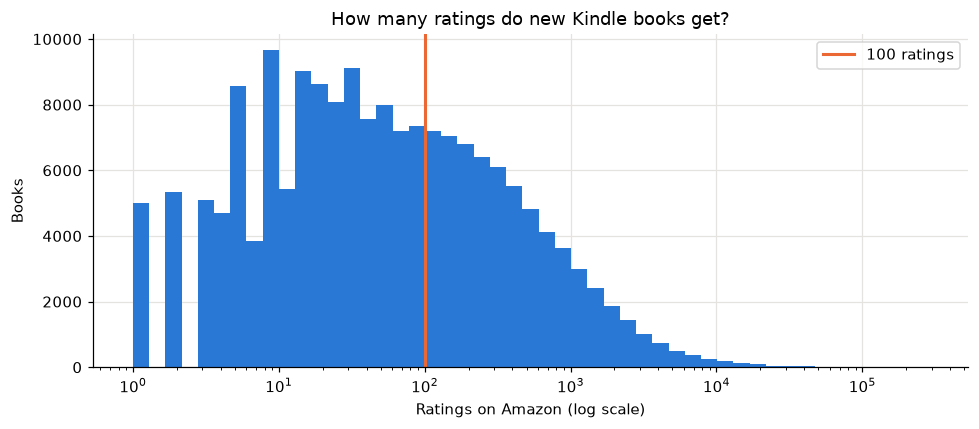

count    176367.0
mean        349.0
std        2038.0
min           1.0
25%          11.0
50%          44.0
75%         206.0
90%         689.0
max      283149.0
Name: rating_number, dtype: float64

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(books["rating_number"], bins=np.logspace(0, np.log10(books["rating_number"].max() + 1), 50), color=BLUE)
ax.axvline(100, color=ORANGE, linewidth=2, label="100 ratings")
ax.set_xscale("log")
ax.set_xlabel("Ratings on Amazon (log scale)")
ax.set_ylabel("Books")
ax.set_title("How many ratings do new Kindle books get?")
ax.legend()
plt.tight_layout()
plt.show()
books["rating_number"].describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(0)

- The number of ratings is extremely uneven: a typical book has **44 ratings** (median), a quarter of the books have 11
  or fewer, a quarter **206 or more**, and the most rated book 283,149.
- On the log scale the books spread evenly around the line of 100 ratings, so 100 is a good dividing point: **36%** of
  the books are above it and **64%** below. Both groups are large enough for the models.

### 8.2 Price, pages and niches

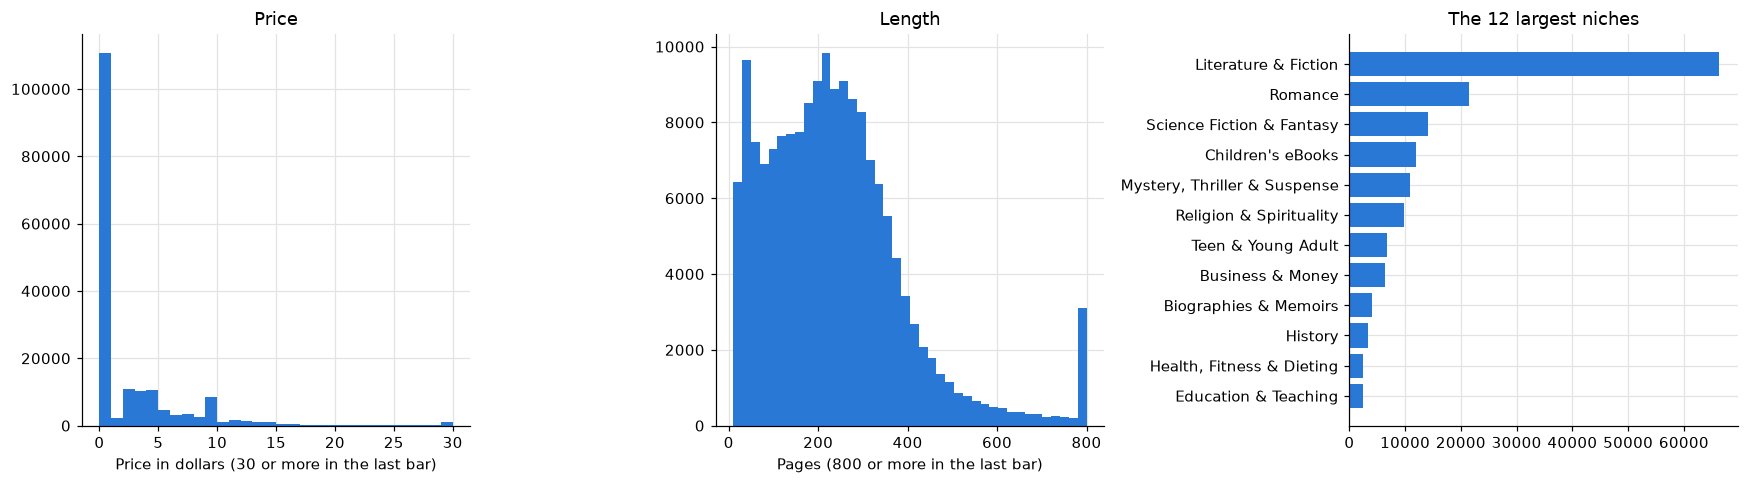

Price 0: 60.1% | up to 5 dollars: 82.1% | more than 10 dollars: 5.5%


,books,share_%
niche,,
Literature & Fiction,66383,37.6
Romance,21415,12.1
Science Fiction & Fantasy,14049,8.0
Children's eBooks,11947,6.8


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(books["price"].clip(upper=30), bins=30, color=BLUE)
axes[0].set_xlabel("Price in dollars (30 or more in the last bar)")
axes[0].set_title("Price")
axes[1].hist(books["pages"].clip(upper=800), bins=40, color=BLUE)
axes[1].set_xlabel("Pages (800 or more in the last bar)")
axes[1].set_title("Length")
sizes = books["niche"].value_counts().head(12).sort_values()
axes[2].barh(sizes.index, sizes.values, color=BLUE)
axes[2].set_title("The 12 largest niches")
plt.tight_layout()
plt.show()
print(f"Price 0: {(books['price'] == 0).mean():.1%} | up to 5 dollars: {(books['price'] <= 5).mean():.1%}"
      f" | more than 10 dollars: {(books['price'] > 10).mean():.1%}")
niche_sizes = pd.DataFrame({"books": books["niche"].value_counts(),
                            "share_%": (books["niche"].value_counts(normalize=True) * 100).round(1)})
niche_sizes.head(4)

- **Price:** most books show a price of 0 (mostly Kindle Unlimited, 7.2) or cost up to 5 dollars; only a few cost more than 10.
- **Length:** a typical book has about 220 pages.
- **Niches:** **Literature & Fiction** is by far the largest niche (66,383 books, 38% of the sample), followed by
  Romance, Science Fiction & Fantasy and Children's eBooks.

## 9. Bivariate exploration

Now I compare the share of books that reach 100 ratings across each feature.

### 9.1 By niche

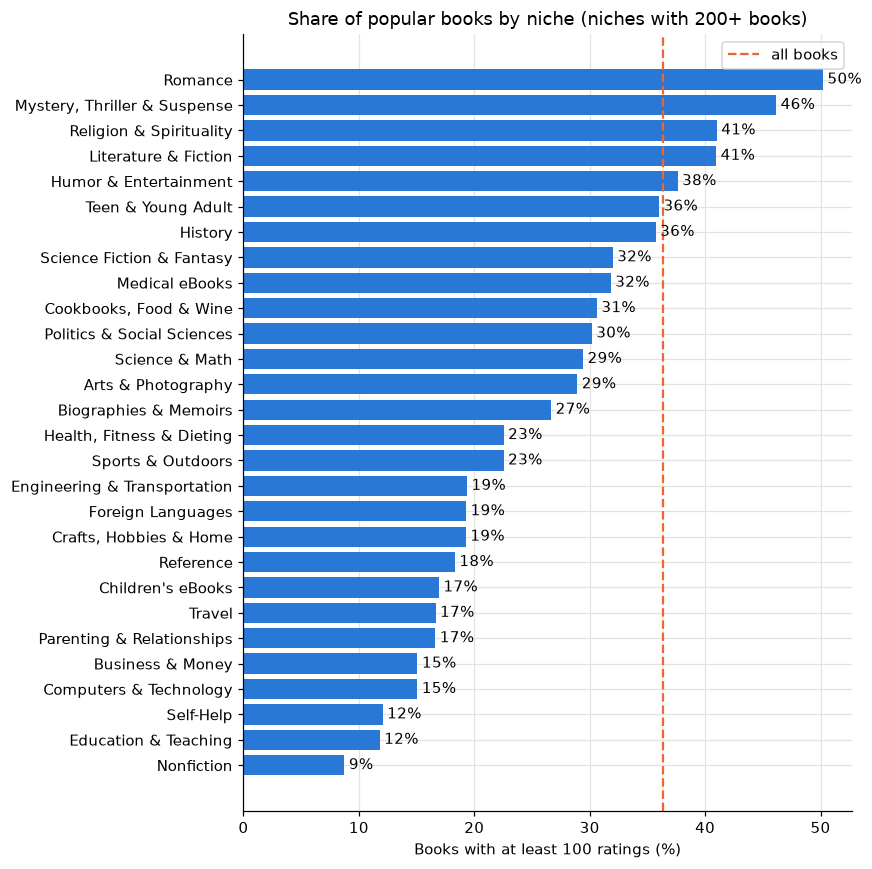

In [29]:
by_niche = books.groupby("niche").agg(books=("popular", "size"), popular_pct=("popular", lambda s: s.mean() * 100))
by_niche = by_niche[by_niche["books"] >= 200].sort_values("popular_pct")

fig, ax = plt.subplots(figsize=(8, 8))
bars = ax.barh(by_niche.index, by_niche["popular_pct"], color=BLUE)
ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.axvline(books["popular"].mean() * 100, color=ORANGE, linestyle="--", label="all books")
ax.set_xlabel("Books with at least 100 ratings (%)")
ax.set_title("Share of popular books by niche (niches with 200+ books)")
ax.legend()
plt.tight_layout()
plt.show()

- **Romance** (50%) and **Mystery, Thriller & Suspense** (46%) are the niches where books reach 100 ratings most often,
  followed by **Religion & Spirituality** and **Literature & Fiction** (41% each).
- The weakest niches are practical non-fiction: **Nonfiction** (9%), **Education & Teaching** (12%), **Self-Help** (12%),
  **Computers & Technology** and **Business & Money** (15%), and **Children's eBooks** (17%).
- So the niche alone changes the chance from about 1 in 10 to 1 in 2.

### 9.2 Self-published or publisher, price, series, author experience and year

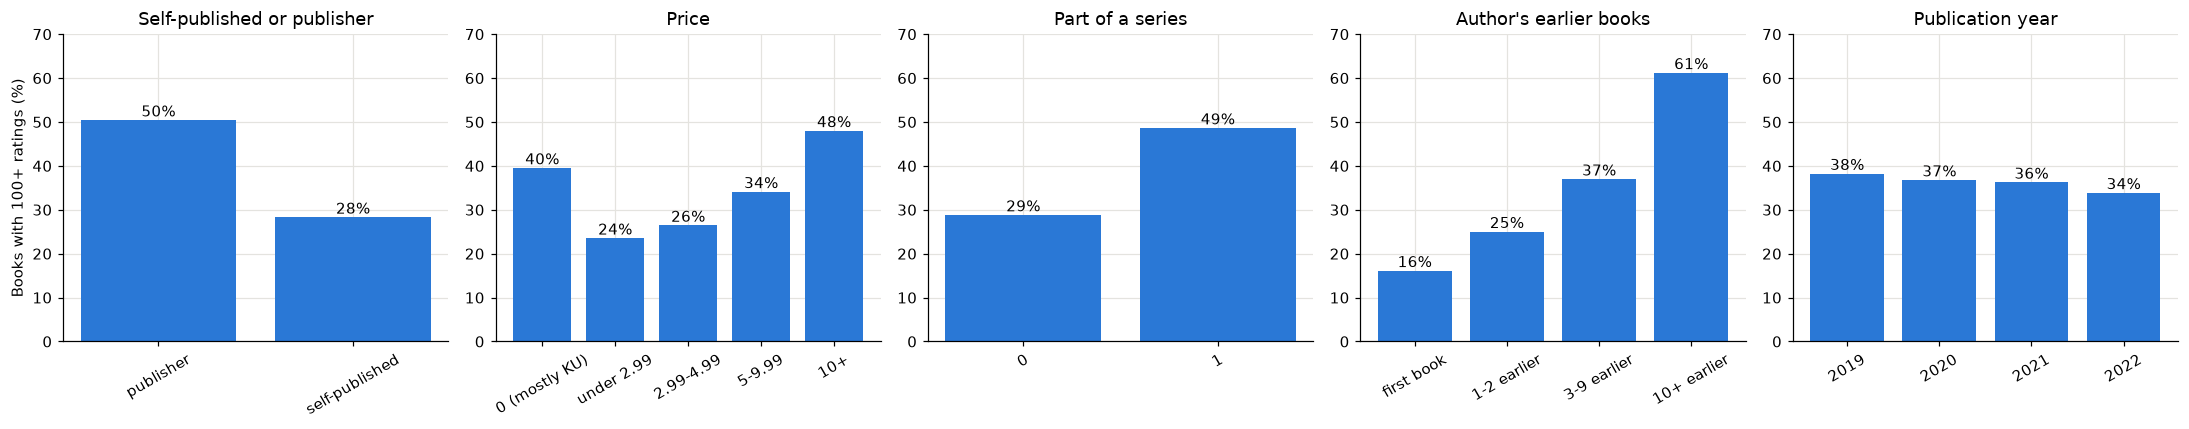

In [30]:
books["price_band"] = pd.cut(books["price"], [-0.01, 0, 2.98, 4.99, 9.99, np.inf],
                             labels=["0 (mostly KU)", "under 2.99", "2.99-4.99", "5-9.99", "10+"])
books["author_experience"] = pd.cut(books["author_earlier_books"], [-1, 0, 2, 9, np.inf],
                                    labels=["first book", "1-2 earlier", "3-9 earlier", "10+ earlier"])
books["publisher_type"] = np.where(books["self_published"] == 1, "self-published", "publisher")

panels = [("publisher_type", "Self-published or publisher"), ("price_band", "Price"), ("is_series", "Part of a series"),
          ("author_experience", "Author's earlier books"), ("publication_year", "Publication year")]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (column, label) in zip(axes, panels):
    share = books.groupby(column, observed=True)["popular"].mean() * 100
    bars = ax.bar(share.index.astype(str), share.values, color=BLUE)
    ax.bar_label(bars, fmt="%.0f%%")
    ax.set_title(label)
    ax.set_ylim(0, 70)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Books with 100+ ratings (%)")
plt.tight_layout()
plt.show()

- **Self-published or publisher:** **50%** of publisher books reach 100 ratings, but only **28%** of self-published books.
- **Price:** books with price 0, mostly Kindle Unlimited (40%), and books from 10 dollars (48%) reach 100 ratings most often; books under 5 dollars least
  (24–26%). The expensive books are mostly publisher books.
- **Series:** books in a series reach 100 ratings much more often (**49%** against 29%).
- **Author's earlier books:** the strongest pattern. A first book reaches 100 ratings in **16%** of cases, an author with
  1–2 earlier books 25%, with 3–9 earlier books 37%, and with **10 or more** earlier books **61%**.
- **Publication year:** older books did a little better (38% in 2019, 34% in 2022), because they had more time to collect
  ratings.

### 9.3 Self-published against publisher books, by niche

Does a publisher change the result within the same niche?

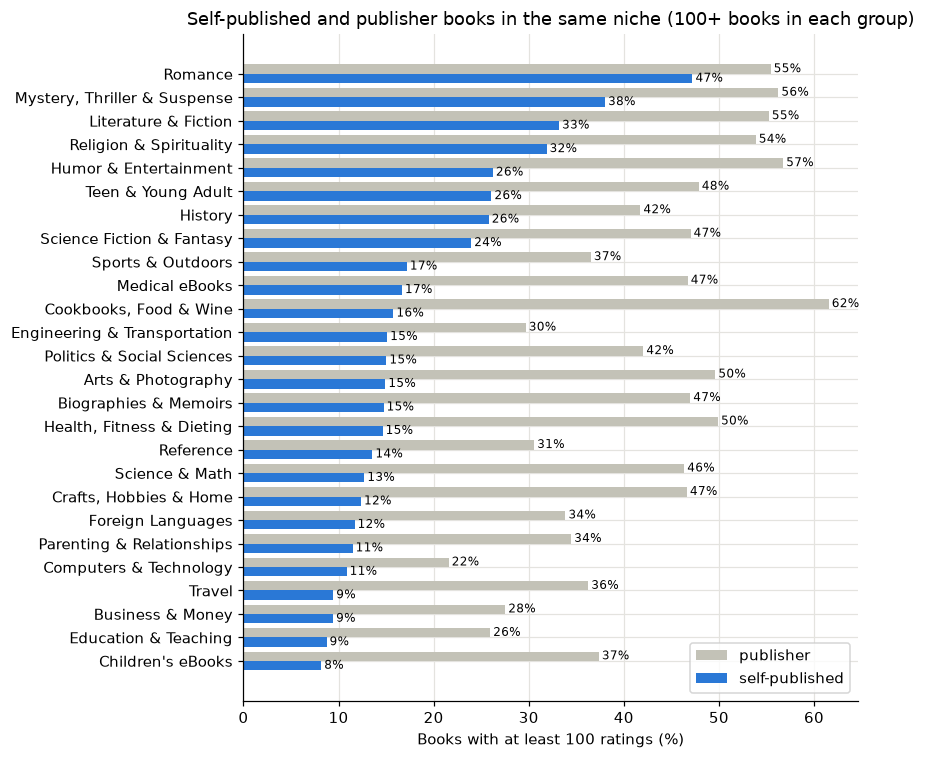

publisher_type,publisher,self-published,gap
niche,,,
Romance,55.0,47.0,8.0
Computers & Technology,22.0,11.0,11.0
Engineering & Transportation,30.0,15.0,15.0
History,42.0,26.0,16.0
Reference,31.0,14.0,17.0
Education & Teaching,26.0,9.0,17.0
Business & Money,28.0,9.0,18.0
"Mystery, Thriller & Suspense",56.0,38.0,18.0
Sports & Outdoors,37.0,17.0,19.0


In [31]:
compare = books.pivot_table(index="niche", columns="publisher_type", values="popular", aggfunc=["mean", "size"])
compare = compare[(compare[("size", "self-published")] >= 100) & (compare[("size", "publisher")] >= 100)]
compare = (compare["mean"] * 100).sort_values("self-published")

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(compare))
bars_publisher = ax.barh(y + 0.2, compare["publisher"], height=0.4, color=GREY, label="publisher")
bars_self = ax.barh(y - 0.2, compare["self-published"], height=0.4, color=BLUE, label="self-published")
ax.bar_label(bars_publisher, fmt="%.0f%%", padding=2, fontsize=8)
ax.bar_label(bars_self, fmt="%.0f%%", padding=2, fontsize=8)
ax.set_yticks(y, compare.index)
ax.set_xlabel("Books with at least 100 ratings (%)")
ax.set_title("Self-published and publisher books in the same niche (100+ books in each group)")
ax.legend()
plt.tight_layout()
plt.show()
compare["gap"] = compare["publisher"] - compare["self-published"]
compare.round(0).sort_values("gap")

- In **every niche** publisher books reach 100 ratings more often than self-published books (`gap` = publisher minus
  self-published, in percentage points).
- The gap is smallest in **Romance** (55% against 47%, 8 points). **Computers & Technology** also has a small gap (11
  points), but there both groups are weak (22% against 11%).
- The best niches for self-published books are **Romance** (47%) and **Mystery, Thriller & Suspense** (38%).
- The gap is largest in non-fiction: **Cookbooks** (62% against 16%, 46 points), **Health**, **Arts & Photography** (50%
  against 15%) and **Biographies** (47% against 15%).
- For a self-publishing author, Romance and Mystery are the niches where self-published books do best.

### 9.4 Correlation between the numeric features

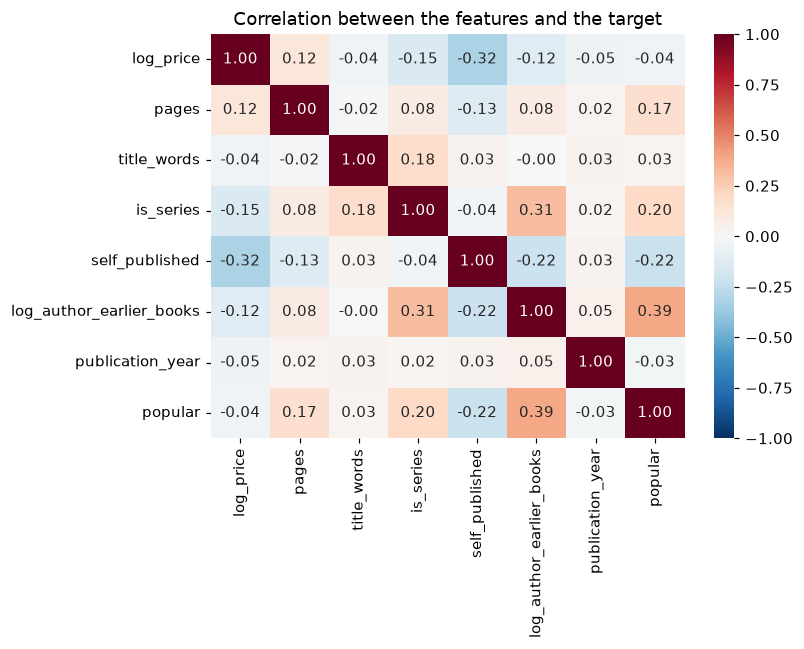

In [32]:
books["log_price"] = np.log1p(books["price"])
books["log_author_earlier_books"] = np.log1p(books["author_earlier_books"])
numeric = ["log_price", "pages", "title_words", "is_series", "self_published", "log_author_earlier_books",
           "publication_year", "popular"]
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(books[numeric].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Correlation between the features and the target")
plt.tight_layout()
plt.show()

- The target `popular` goes most with the **author's earlier books** (0.39), then with being **self-published** (−0.22,
  less popular), being part of a **series** (0.20) and the number of **pages** (0.17).
- Price, title length and year are hardly related to the target on their own (between −0.04 and 0.03).
- No two features are strongly related to each other (the highest are −0.32, price and self-published, and 0.31, series
  and author's earlier books), so all of them can stay in the models.

### 9.5 Average number of pages by niche

In 7.3 I saw the length of all books together. Now I check whether the typical length differs from niche to niche, because
the length is a decision an author makes for a book in a given niche.

- `groupby("niche")` makes one group per niche, and `.agg()` calculates the number of books, the **mean** and the
  **median** of the pages, and the share of popular books for each group.
- I show both the mean and the median, because a few very long books can pull the mean up; the median is not affected
  by them.
- Books with an empty page count (7.3) are left out of the mean and the median automatically. As in 9.1, I show only
  niches with at least 200 books.

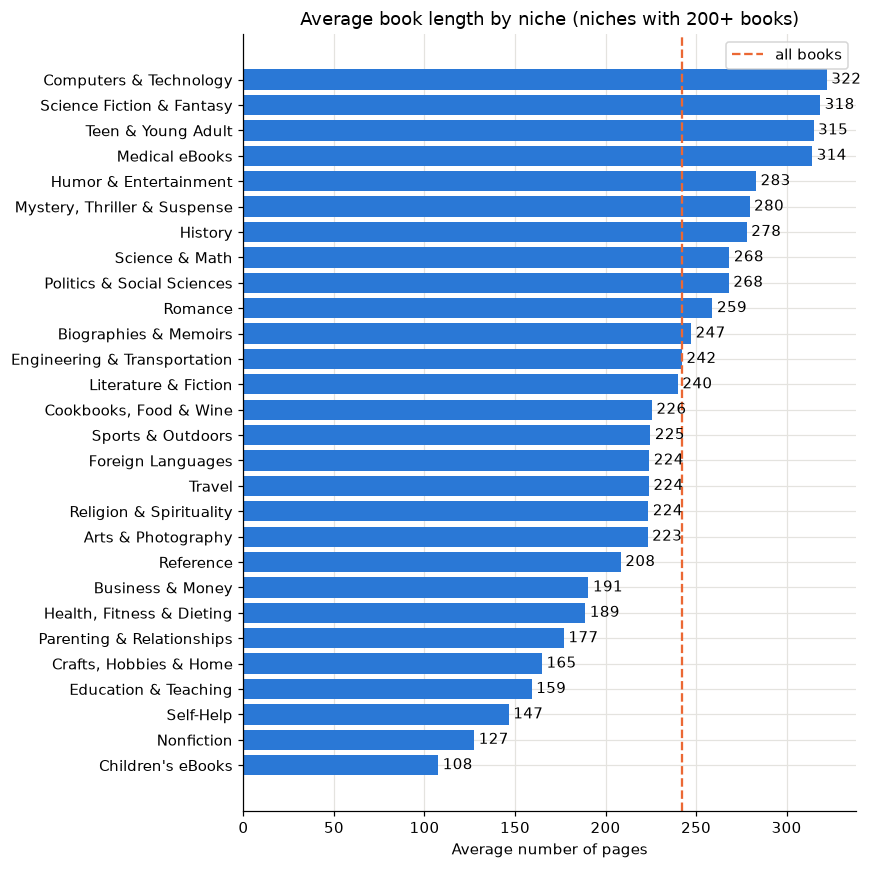

All books: mean 242 pages | median 219 pages


,books,mean_pages,median_pages,popular_pct
niche,,,,
Computers & Technology,1547,322.0,244.0,15.0
Science Fiction & Fantasy,14049,318.0,285.0,32.0
Teen & Young Adult,6750,315.0,291.0,36.0
Medical eBooks,242,314.0,224.0,32.0
Humor & Entertainment,1489,283.0,240.0,38.0
"Mystery, Thriller & Suspense",10903,280.0,251.0,46.0
History,3427,278.0,250.0,36.0
Science & Math,938,268.0,229.0,29.0
Politics & Social Sciences,2088,268.0,241.0,30.0


In [33]:
pages_by_niche = books.groupby("niche").agg(
    books=("pages", "size"),
    mean_pages=("pages", "mean"),
    median_pages=("pages", "median"),
    popular_pct=("popular", lambda s: s.mean() * 100),
)
pages_by_niche = pages_by_niche[pages_by_niche["books"] >= 200].sort_values("mean_pages")

fig, ax = plt.subplots(figsize=(8, 8))
bars = ax.barh(pages_by_niche.index, pages_by_niche["mean_pages"], color=BLUE)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.axvline(books["pages"].mean(), color=ORANGE, linestyle="--", label="all books")
ax.set_xlabel("Average number of pages")
ax.set_title("Average book length by niche (niches with 200+ books)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"All books: mean {books['pages'].mean():.0f} pages | median {books['pages'].median():.0f} pages")
pages_by_niche.sort_values("mean_pages", ascending=False).round(0)

- An average book has **242 pages** (median 219), but the niches differ a lot.
- The longest books on average are in **Computers & Technology** (322 pages), **Science Fiction & Fantasy** (318),
  **Teen & Young Adult** (315) and **Medical eBooks** (314).
- The shortest are in **Children's eBooks** (108), **Nonfiction** (127), **Self-Help** (147) and **Education & Teaching**
  (159).
- The mean and the median can tell a different story. In **Computers & Technology** the mean is 322 but the median only
  244, so a few very long books raise the mean. By the median, the longest typical books are in **Teen & Young Adult**
  (291) and **Science Fiction & Fantasy** (285). A typical **children's** book has only 42 pages.
- Length alone does not make a book popular: **Computers & Technology** has the highest mean, but only 15% of its books
  reach 100 ratings, while **Romance** has 259 pages on average and reaches 50%.

### 9.6 Are ratings related to sales?

The first question is whether the number of ratings says anything about the number of **books sold** in a
niche. I must start with a limit: I look for any column or `details` field whose name mentions sales, rank or units.

In [34]:
all_fields = list(schema.names()) + [field.name for field in schema["details"].fields]
found = [name for name in all_fields if re.search(r"(?i)sale|sold|rank|unit|revenue|income", name)]
print(f"Columns and details fields checked: {len(all_fields)}")
print("Fields about sales:", found)

Columns and details fields checked: 50
Fields about sales: []


The list is empty: **the data has no copies sold and no sales rank**. So I cannot measure this relation directly. I can
do two indirect checks.

**Check 1: the bestseller label.** Amazon's bestseller rankings follow customer activity (9.13), and the Kaggle file from 7.2
has the *Best Seller* label. If ratings follow sales, books with more ratings should have the label more often. I use the whole catalog
(`catalog` from 5.3), because bestsellers are rare.

- `.merge()` keeps the books found in both files; `pd.cut()` makes groups by the number of ratings.

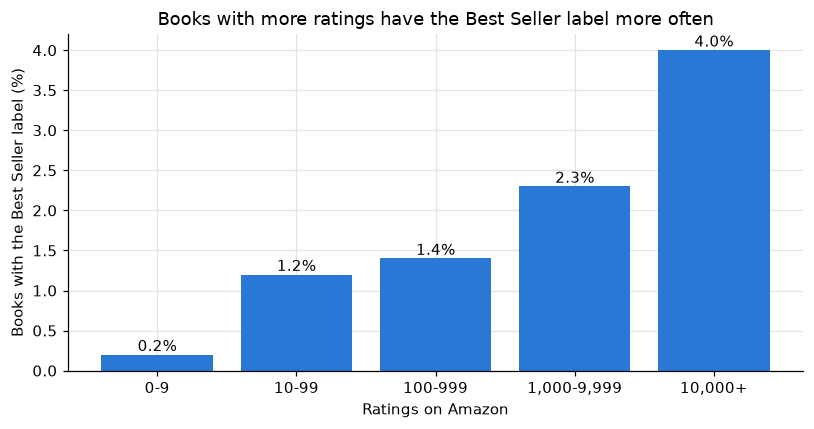

Books found in both files: 68,663 | bestsellers: 1,207


,books,bestsellers,bestseller_pct
ratings_group,,,
0-9,455,1,0.2
10-99,9945,116,1.2
100-999,34114,492,1.4
"1,000-9,999",21397,489,2.3
"10,000+",2752,109,4.0


In [35]:
labels = kaggle[["asin", "isBestSeller"]].rename(columns={"asin": "parent_asin"})
catalog_niche = catalog.select(
    "parent_asin", "rating_number",
    pl.col("categories").list.get(1, null_on_oob=True).alias("level_2"),
    pl.col("categories").list.get(2, null_on_oob=True).alias("niche"),
).to_pandas()
with_label = catalog_niche.merge(labels, on="parent_asin")
with_label["ratings_group"] = pd.cut(with_label["rating_number"], [-1, 9, 99, 999, 9999, np.inf],
                                     labels=["0-9", "10-99", "100-999", "1,000-9,999", "10,000+"])
bestseller_by_ratings = with_label.groupby("ratings_group", observed=True)["isBestSeller"].agg(
    books="size", bestsellers="sum", bestseller_pct=lambda s: s.mean() * 100).round({"bestseller_pct": 1})

fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(bestseller_by_ratings.index.astype(str), bestseller_by_ratings["bestseller_pct"], color=BLUE)
ax.bar_label(bars, fmt="%.1f%%")
ax.set_xlabel("Ratings on Amazon")
ax.set_ylabel("Books with the Best Seller label (%)")
ax.set_title("Books with more ratings have the Best Seller label more often")
plt.tight_layout()
plt.show()
print(f"Books found in both files: {len(with_label):,} | bestsellers: {with_label['isBestSeller'].sum():,}")
bestseller_by_ratings

- The share of bestsellers rises with the number of ratings: **0.2%** with 0–9 ratings, **1.2%** with 10–99, **1.4%** with 100–999,
  **2.3%** with 1,000–9,999 and **4.0%** with 10,000 or more.
- This agrees with the idea that more ratings go with more sales, but it is a weak check: even among the most rated books,
  only 4.0% have the label.

**Check 2: the same comparison by niche.** For each niche I compare the median number of ratings with the share of
bestsellers. The **Spearman correlation** compares the order of the niches: +1 means the same order, 0 no relation.

In [36]:
niche_label = with_label[(with_label["level_2"] == "Kindle eBooks") & with_label["niche"].isin(genres)]
niche_check = niche_label.groupby("niche").agg(books=("isBestSeller", "size"), bestsellers=("isBestSeller", "sum"),
                                               median_ratings=("rating_number", "median"),
                                               bestseller_pct=("isBestSeller", lambda s: s.mean() * 100))
niche_check = niche_check[niche_check["books"] >= 300].sort_values("bestseller_pct", ascending=False)
print("Niches compared:", len(niche_check))
print("Spearman correlation:", round(niche_check["median_ratings"].corr(niche_check["bestseller_pct"], method="spearman"), 2))
pd.concat([niche_check.head(4), niche_check.tail(4)]).round(1)

Niches compared: 26
Spearman correlation: -0.35


,books,bestsellers,median_ratings,bestseller_pct
niche,,,,
Medical eBooks,453,17,275.0,3.8
Reference,1178,36,163.5,3.1
Children's eBooks,1264,38,841.5,3.0
"Crafts, Hobbies & Home",880,26,235.0,3.0
Sports & Outdoors,1886,18,263.5,1.0
"Mystery, Thriller & Suspense",1849,13,1954.0,0.7
Science Fiction & Fantasy,2499,10,1515.0,0.4
Romance,2923,8,1220.0,0.3


- Across **26 niches** the correlation is **−0.35**: niches with more ratings have the label somewhat **less** often. **Romance** has a
  median of 1,220 ratings and 0.3% bestsellers, while **Medical eBooks** have 275 ratings and 3.8%.
- So this check **does not confirm** that ratings show sales at the level of a niche. The label is probably a poor measure for
  comparing niches: it is given within Amazon's categories, and the Kaggle file holds only a limited number of books per category.
- **Conclusion for this question:** for single books, more ratings go together with the bestseller label; for niches
  I cannot show the relation with this data. Ratings remain a measure of **reader response**, and copies sold stay an assumption.

**What ratings can show about a niche.** Without sales, I can still compare each niche's **share of all books** with its
**share of all ratings**. A niche with a larger share of ratings than of books gets more reader response per book.

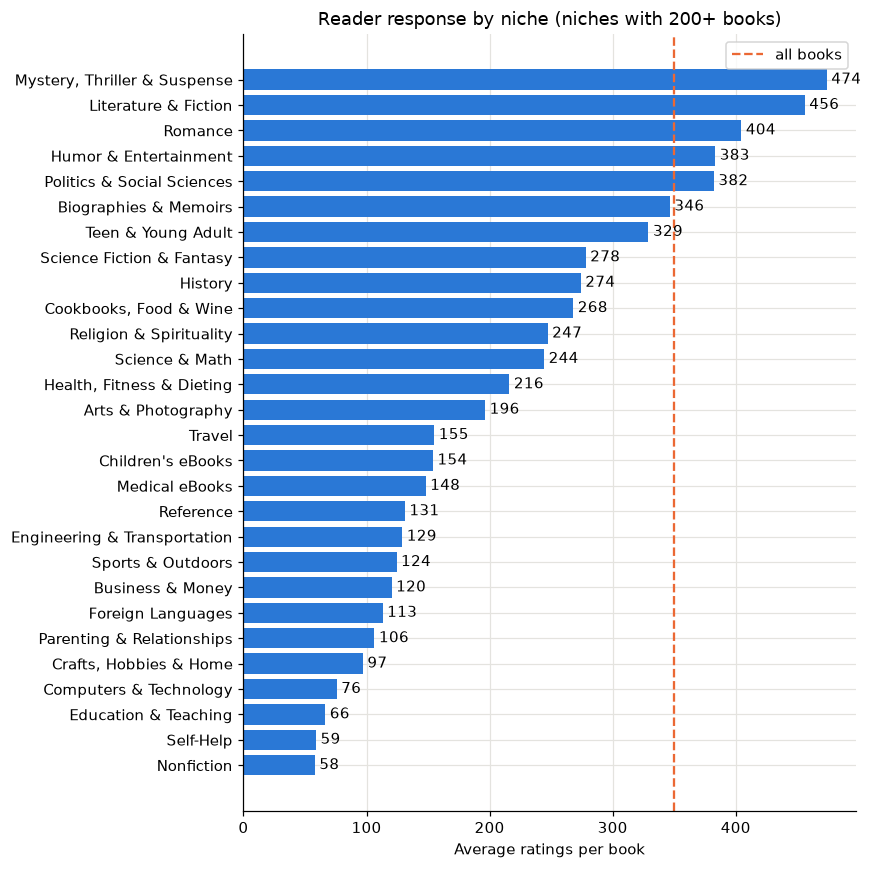

All books: 349 ratings per book on average


,books,books_%,ratings_%,ratings_per_book,median_ratings
niche,,,,,
"Mystery, Thriller & Suspense",10903,6.2,8.4,473.9,79.0
Literature & Fiction,66383,37.6,49.1,456.0,57.0
Romance,21415,12.1,14.1,404.5,101.0
Humor & Entertainment,1489,0.8,0.9,383.3,42.0
Computers & Technology,1547,0.9,0.2,75.7,20.0
Education & Teaching,2381,1.4,0.3,66.5,11.0
Self-Help,481,0.3,0.0,59.0,16.0
Nonfiction,366,0.2,0.0,58.0,8.0


In [37]:
niche_demand = books.groupby("niche").agg(books=("rating_number", "size"), ratings=("rating_number", "sum"),
                                          median_ratings=("rating_number", "median"))
niche_demand = niche_demand[niche_demand["books"] >= 200]
niche_demand["books_%"] = niche_demand["books"] / books.shape[0] * 100
niche_demand["ratings_%"] = niche_demand["ratings"] / books["rating_number"].sum() * 100
niche_demand["ratings_per_book"] = niche_demand["ratings"] / niche_demand["books"]
niche_demand = niche_demand.sort_values("ratings_per_book", ascending=False)

plot_data = niche_demand.sort_values("ratings_per_book")
fig, ax = plt.subplots(figsize=(8, 8))
bars = ax.barh(plot_data.index, plot_data["ratings_per_book"], color=BLUE)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.axvline(books["rating_number"].mean(), color=ORANGE, linestyle="--", label="all books")
ax.set_xlabel("Average ratings per book")
ax.set_title("Reader response by niche (niches with 200+ books)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"All books: {books['rating_number'].mean():.0f} ratings per book on average")
demand_columns = ["books", "books_%", "ratings_%", "ratings_per_book", "median_ratings"]
pd.concat([niche_demand[demand_columns].head(4), niche_demand[demand_columns].tail(4)]).round(1)

- An average book has **349 ratings**. **Mystery, Thriller & Suspense** (474 per book), **Literature & Fiction** (456) and **Romance**
  (405) are above this.
- These niches have a larger share of ratings than of books: for example Literature & Fiction has 37.6% of the books and 49.1%
  of the ratings.
- **Computers & Technology** (76), **Education & Teaching** (67) and **Self-Help** (59) get far fewer ratings per book.

### 9.7 Does the price change the percentage the author receives?

Yes, and this comes from **contract rules**, not from the data. I write the rules as a small function and then look at
what they mean.

| Route | Rule I use | Source |
|---|---|---|
| **Self-published, 35% option** | 35% of the list price | [KDP eBook Royalties](https://kdp.amazon.com/en_US/help/topic/G200644210) |
| **Self-published, 70% option** | 70% of (list price − delivery cost), only for prices in the 70% band | same page |
| **70% band on Amazon.com** | **2.99–9.99 dollars until July 2026** (the time of my data), 2.99–12.99 dollars since 7 July 2026 | [KDP List Price Requirements](https://kdp.amazon.com/help/topic/G200634560) |
| **Delivery cost** | 0.15 dollars per MB of the book file | [KDP Digital Book Pricing](https://kdp.amazon.com/help/topic/G200634500) |
| **Publisher contract** | 25% of what the publisher receives, and the publisher receives 70% of the list price, so **17.5% of the list price** | [Authors Guild, 2011](https://authorsguild.org/news/e-book-royalty-math-the-house-always-wins-2/) |

These rules are simplified: I use US prices without VAT, and I leave out literary agents, advances and contracts that
differ from the standard. When both self-publishing options are possible, I take the better one for the author.

The size of the file matters for the delivery cost, so I read `File size` from the original file. It is the only new
field I need. A book without a file size gets the median size.

Books without a file size: 2,813
Median file size: 2.40 MB = 0.36 dollars delivery cost per copy


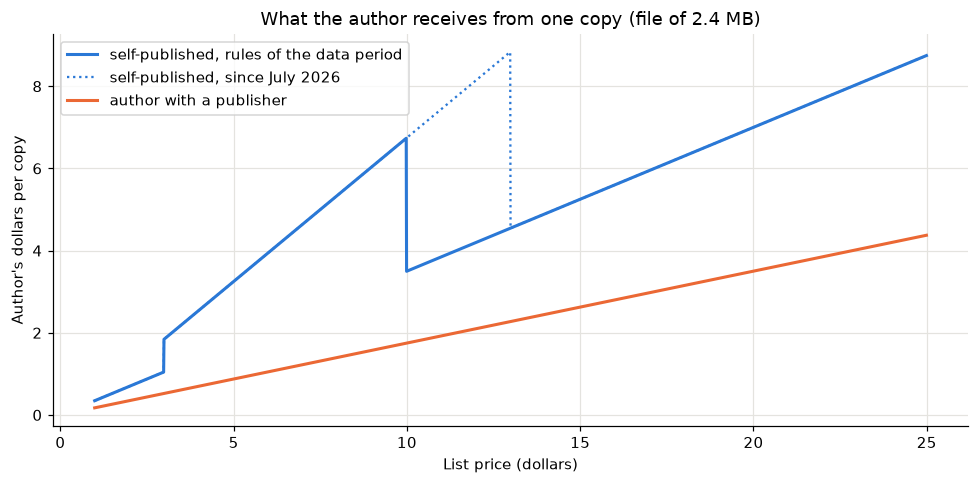

Price at 35% that pays the same as 9.99 dollars at 70%: 19.26 dollars


,price,self-pub $ (data period),self-pub % (data period),self-pub $ (since July 2026),publisher author $,publisher author %
0,0.99,0.35,35.00,0.35,0.17,17.5
1,1.99,0.70,35.00,0.70,0.35,17.5
2,2.99,1.84,61.57,1.84,0.52,17.5
3,4.99,3.24,64.95,3.24,0.87,17.5
4,7.99,5.34,66.85,5.34,1.40,17.5
5,9.99,6.74,67.48,6.74,1.75,17.5
6,10.99,3.85,35.00,7.44,1.92,17.5
7,12.99,4.55,35.00,8.84,2.27,17.5
8,14.99,5.25,35.00,5.25,2.62,17.5
9,19.99,7.00,35.00,7.00,3.50,17.5


In [38]:
DELIVERY_PER_MB = 0.15
PUBLISHER_SHARE = 0.25 * 0.70

file_sizes = (raw.select("parent_asin", pl.col("details").struct.field("File size").alias("file_size"))
              .collect(engine="streaming").to_pandas())
file_sizes["file_mb"] = pd.to_numeric(file_sizes["file_size"].str.replace(",", "").str.extract(r"([\d.]+)\s*KB")[0],
                                      errors="coerce") / 1024
books["file_mb"] = books["parent_asin"].map(file_sizes.set_index("parent_asin")["file_mb"])
print(f"Books without a file size: {books['file_mb'].isna().sum():,}")
books["file_mb"] = books["file_mb"].fillna(books["file_mb"].median())
MEDIAN_MB = books["file_mb"].median()
print(f"Median file size: {MEDIAN_MB:.2f} MB = {MEDIAN_MB * DELIVERY_PER_MB:.2f} dollars delivery cost per copy")


def self_published_per_copy(price, file_mb, top_of_band=9.99):
    # Dollars for the author from one copy sold; the author takes the better of the two options.
    price, file_mb = np.asarray(price, dtype=float), np.asarray(file_mb, dtype=float)
    option_35 = 0.35 * price
    option_70 = 0.70 * (price - DELIVERY_PER_MB * file_mb)
    in_band = (price >= 2.99) & (price <= top_of_band)
    return np.where(in_band, np.maximum(option_35, option_70), option_35)


example_prices = np.array([0.99, 1.99, 2.99, 4.99, 7.99, 9.99, 10.99, 12.99, 14.99, 19.99, 24.99])
rules = pd.DataFrame({"price": example_prices})
rules["self-pub $ (data period)"] = self_published_per_copy(example_prices, MEDIAN_MB)
rules["self-pub % (data period)"] = rules["self-pub $ (data period)"] / example_prices * 100
rules["self-pub $ (since July 2026)"] = self_published_per_copy(example_prices, MEDIAN_MB, top_of_band=12.99)
rules["publisher author $"] = example_prices * PUBLISHER_SHARE
rules["publisher author %"] = PUBLISHER_SHARE * 100

price_line = np.arange(0.99, 25.0, 0.01)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(price_line, self_published_per_copy(price_line, MEDIAN_MB), color=BLUE, linewidth=2, label="self-published, rules of the data period")
ax.plot(price_line, self_published_per_copy(price_line, MEDIAN_MB, 12.99), color=BLUE, linestyle=":", label="self-published, since July 2026")
ax.plot(price_line, price_line * PUBLISHER_SHARE, color=ORANGE, linewidth=2, label="author with a publisher")
ax.set_xlabel("List price (dollars)")
ax.set_ylabel("Author's dollars per copy")
ax.set_title(f"What the author receives from one copy (file of {MEDIAN_MB:.1f} MB)")
ax.legend()
plt.tight_layout()
plt.show()

match = 0.70 * (9.99 - DELIVERY_PER_MB * MEDIAN_MB) / 0.35
print(f"Price at 35% that pays the same as 9.99 dollars at 70%: {match:.2f} dollars")
rules.round(2)

- For a **self-published** author the percentage depends strongly on the price: **35%** under 2.99 dollars, about **62–67%** from 2.99 to
  9.99 dollars (the delivery cost of 0.36 dollars is already taken off), and **35%** again above 9.99.
- **The jump at 9.99 was large:** at 9.99 dollars the author received **6.74 dollars**, and at 10.99 only **3.85**. A book at 35%
  had to cost **19.26 dollars** to pay the same as 9.99 dollars at 70%.
- **The rule has changed:** since July 2026 a book at 12.99 dollars pays **8.84 dollars** instead of 4.55. My data is from 2023, so
  the income estimates use the old rule.
- With the standard **publisher** contract the percentage does not depend on the price: always **17.5%**. At 4.99 dollars the author
  receives 0.87 dollars, against 3.24 when self-publishing.

### 9.8 Where do real books stand?

Now I apply the rules to the books. Only books with a **known price** are used (`price_known` from 7.2). For Kindle
Unlimited books the price is hidden and the author is paid per page read, which the data does not show.

- `author_per_copy` is the author's dollars from one copy; `author_pct` is that amount as a percentage of the price.
- The price groups follow the limits of the rules: 2.99, 9.99 and 12.99 dollars.

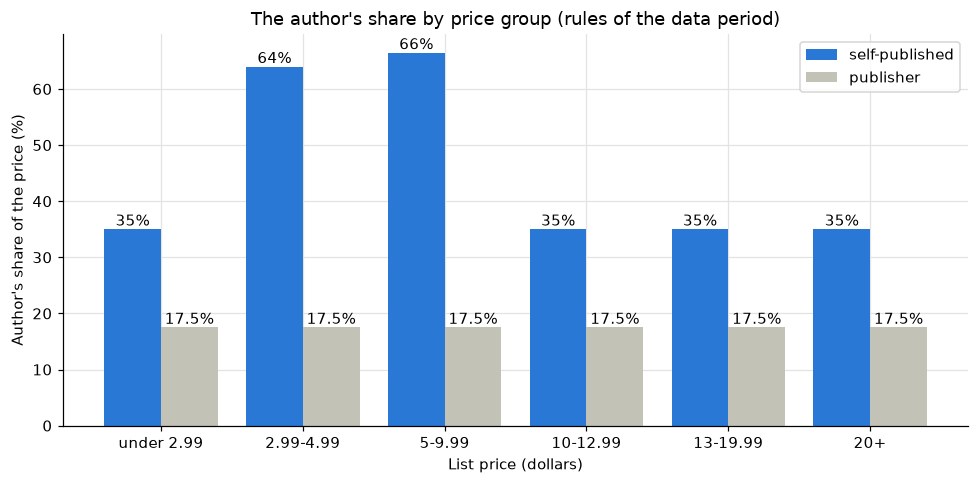

Books with a known price: 70,442 of 176,367


books  median_price  median_author_pct  median_author_dollars  share_of_group_%
publisher_type price_group                                                                                 
publisher      under 2.99    2853           1.0               17.5                    0.2               7.8
               2.99-4.99    12596           4.0               17.5                    0.7              34.4
               5-9.99       12579           8.5               17.5                    1.5              34.4
               10-12.99      3709          12.0               17.5                    2.1              10.1
               13-19.99      3379          15.0               17.5                    2.6               9.2
               20+           1484          29.5               17.5                    5.2               4.1
self-published under 2.99    4348           1.0               35.0                    0.3              12.8
               2.99-4.99    18829           4.0               64.0                    2.4              55.6
               5-9.99        9480           8.0               66.4                    5.2              28.0
               10-12.99       348          12.0               35.0                    4.2               1.0
               13-19.99       488          16.0               35.0                    5.6               1.4
               20+            349          30.0               35.0                   10.5               1.0

In [39]:
paid = books[books["price_known"]].copy()
paid["author_per_copy"] = np.where(paid["self_published"] == 1,
                                   self_published_per_copy(paid["price"], paid["file_mb"]),
                                   paid["price"] * PUBLISHER_SHARE)
paid["author_pct"] = paid["author_per_copy"] / paid["price"] * 100
paid["price_group"] = pd.cut(paid["price"], [0, 2.98, 4.99, 9.99, 12.99, 19.99, np.inf],
                             labels=["under 2.99", "2.99-4.99", "5-9.99", "10-12.99", "13-19.99", "20+"])

share_table = paid.groupby(["publisher_type", "price_group"], observed=True).agg(
    books=("price", "size"), median_price=("price", "median"),
    median_author_pct=("author_pct", "median"), median_author_dollars=("author_per_copy", "median"))
share_table["share_of_group_%"] = share_table["books"] / share_table.groupby(level=0)["books"].transform("sum") * 100

chart = share_table["median_author_pct"].unstack(0)
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(chart))
bars_self = ax.bar(x - 0.2, chart["self-published"], width=0.4, color=BLUE, label="self-published")
bars_publisher = ax.bar(x + 0.2, chart["publisher"], width=0.4, color=GREY, label="publisher")
ax.bar_label(bars_self, fmt="%.0f%%")
ax.bar_label(bars_publisher, fmt="%.1f%%")
ax.set_xticks(x, chart.index)
ax.set_xlabel("List price (dollars)")
ax.set_ylabel("Author's share of the price (%)")
ax.set_title("The author's share by price group (rules of the data period)")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Books with a known price: {len(paid):,} of {len(books):,}")
share_table.round(1)

- **Self-published** authors keep the most at **5–9.99 dollars (66.4%)** and **2.99–4.99 dollars (64.0%)**. These two groups hold **83.6%**
  of the self-published books with a known price, so most authors already price inside the best range.
- **12.8%** of the self-published books cost under 2.99 dollars, where the author keeps only 35%.
- Above 9.99 dollars the share falls to **35%**, and only 3.4% of the self-published books are there.
- With the assumed publisher contract the author receives **17.5%** in every group, so **82.5%** of the price goes to the publisher
  and the store.

### 9.9 Ratings through time

`rating_number` is one total. To see **years**, I need dates. I already have them in `Kindle_Store_0core.csv`, where every row is
one review with its date. I read it with Polars, count the rows per year for the whole file and for my books, and compare the
rows of each book with its `rating_number`.

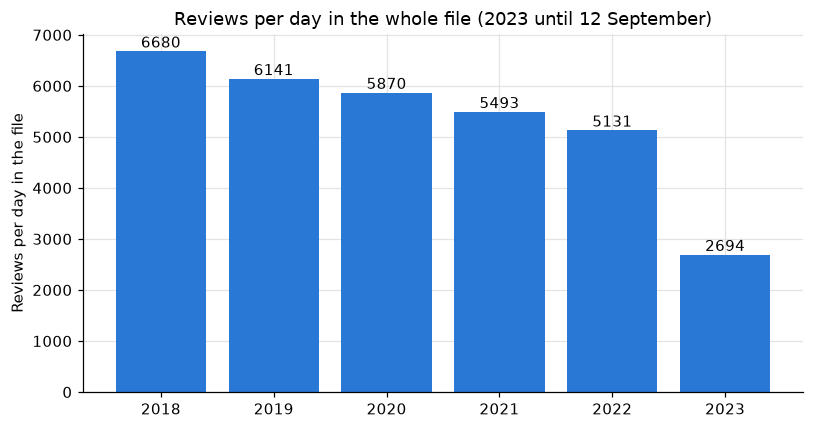

,all_reviews,my_books,all_reviews_per_day
year,,,
2018,2438263,431,6680.0
2019,2241500,398937,6141.0
2020,2148567,576640,5870.0
2021,2004929,623183,5493.0
2022,1872698,614131,5131.0
2023,686968,125910,2694.0


In [40]:
reviews_raw = (pl.scan_csv(RAW_FILE.parent / "Kindle_Store_0core.csv", schema_overrides={"timestamp": pl.Int64})
               .select("parent_asin", pl.from_epoch("timestamp", time_unit="ms").dt.date().alias("day")))
whole_file = (reviews_raw.group_by(pl.col("day").dt.year().alias("year")).agg(pl.len().alias("all_reviews"))
              .collect(engine="streaming").to_pandas().set_index("year").sort_index())
dated = (reviews_raw.filter(pl.col("parent_asin").is_in(books["parent_asin"].to_list()))
         .collect(engine="streaming").to_pandas())
dated["day"] = pd.to_datetime(dated["day"])
dated["year"] = dated["day"].dt.year
LAST_DAY = dated["day"].max()

by_year = whole_file.loc[2018:2023].join(dated["year"].value_counts().rename("my_books")).fillna(0).astype(int)
days = pd.Series(365, index=by_year.index)
days.loc[2020] = 366
days.loc[2023] = (LAST_DAY - pd.Timestamp("2022-12-31")).days
by_year["all_reviews_per_day"] = (by_year["all_reviews"] / days).round(0)

fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(by_year.index.astype(str), by_year["all_reviews_per_day"], color=BLUE)
ax.bar_label(bars, fmt="%.0f")
ax.set_ylabel("Reviews per day in the file")
ax.set_title(f"Reviews per day in the whole file (2023 until {LAST_DAY:%d %B})")
plt.tight_layout()
plt.show()
by_year

- Reviews per day fall slowly from **6,680** in 2018 to **5,131** in 2022, then drop to **2,694** in 2023.
- The file ends on 12 September 2023, and such a sudden fall suggests that **2023 is incomplete**. It is also not a full year, so I
  cannot use it for yearly results.

**Rule.** I use only **complete years, up to 31 December 2022**.

- Reviews from 2023 are removed from every yearly calculation.
- `rating_number` is one total that also contains 2023, so I keep only the part that belongs to the years up to 2022: the
  book's `rating_number` × its reviews up to 2022 ÷ all its reviews in the file. This is `ratings_to_2022`.
- For yearly averages a book must have at least **one full year** on Amazon by the end of 2022, so it must be published by
  31 December 2021 (`full_year`).

In [41]:
END_2022 = pd.Timestamp("2022-12-31")
books["reviews_in_file"] = books["parent_asin"].map(dated["parent_asin"].value_counts()).fillna(0).astype(int)
books["ratings_per_review"] = books["rating_number"] / books["reviews_in_file"].replace(0, np.nan)

reviews_before = len(dated)
dated = dated[dated["year"] <= 2022].copy()
books["reviews_to_2022"] = books["parent_asin"].map(dated["parent_asin"].value_counts()).fillna(0).astype(int)
books["ratings_to_2022"] = books["reviews_to_2022"] * books["ratings_per_review"]
books["full_year"] = pd.to_datetime(books["published"]) <= pd.Timestamp("2021-12-31")

print(f"Reviews of my books: {reviews_before:,} -> {len(dated):,} after removing 2023 | last day: {dated['day'].max():%d %B %Y}")
print(f"Books without any review in the file: {(books['reviews_in_file'] == 0).sum():,}")
print(f"Median Amazon ratings per review in the file: {books['ratings_per_review'].median():.0f}")
print(f"Books with at least one full year: {books['full_year'].sum():,} of {len(books):,}")
print(f"Share of all Amazon ratings that I place up to 2022: {books['ratings_to_2022'].sum() / books['rating_number'].sum():.1%}")
books.groupby("publication_year").agg(books=("price", "size"), reviews_to_2022=("reviews_to_2022", "sum"),
                                      full_year=("full_year", "mean")).round(2)

Reviews of my books: 2,340,816 -> 2,214,906 after removing 2023 | last day: 31 December 2022
Books without any review in the file: 209
Median Amazon ratings per review in the file: 11
Books with at least one full year: 135,991 of 176,367
Share of all Amazon ratings that I place up to 2022: 92.8%


,books,reviews_to_2022,full_year
publication_year,,,
2019,43087,647767,1.0
2020,48237,650804,1.0
2021,44667,551879,1.0
2022,40376,364456,0.0


- **2,214,906** reviews of my books remain, and the last day is now **31 December 2022**.
- A typical book has **11 Amazon ratings for each review** in the file, so I use the file for **timing** and `rating_number` for the size.
- I place **92.8%** of all Amazon ratings of my books in the years up to 2022.
- **135,991** of the 176,367 books have at least one full year. The books from 2022 stay in the year-by-year heatmap, but not in the
  yearly averages.

### 9.10 An estimate of yearly income

Income cannot be read from the data, so I **estimate** it for books with at least one full year on Amazon:

1. **Ratings per year** = `ratings_to_2022` ÷ years on Amazon until 31 December 2022.
2. **Copies per year** = ratings per year × **buyers per rating**.
3. **Yearly income of the author** = copies per year × the author's dollars per copy (9.8).

Nobody knows the true number of buyers per rating. One
[analysis of 20 bestsellers](https://fortelabs.com/blog/how-i-used-amazon-reviews-to-predict-sales-of-my-book/) found that about
1.5% of buyers leave a review (from 0.3% to 4.8%), about 67 buyers per review (from 21 to 333). These are very successful books,
and a review is not exactly a rating, so this is only a rough guide. I show **20, 50 and 100 buyers per rating**. I use only
books with a real list price, because authors of Kindle Unlimited books are mostly paid per page read.

In [42]:
SCENARIOS = [20, 50, 100]
BUYERS_PER_RATING = 50     # the middle scenario, used in the tables and charts below

priced = books[books["price_known"] & books["full_year"] & books["ratings_to_2022"].notna()].copy()
priced["author_per_copy"] = np.where(priced["self_published"] == 1,
                                     self_published_per_copy(priced["price"], priced["file_mb"]),
                                     priced["price"] * PUBLISHER_SHARE)
priced["years_on_amazon"] = (END_2022 - pd.to_datetime(priced["published"])).dt.days / 365.25
priced["ratings_per_year"] = priced["ratings_to_2022"] / priced["years_on_amazon"]
priced["income_per_buyer_rating"] = priced["ratings_per_year"] * priced["author_per_copy"]
priced["yearly_income"] = priced["income_per_buyer_rating"] * BUYERS_PER_RATING
paid = priced.copy()
paid["price_group"] = pd.cut(paid["price"], [0, 2.98, 4.99, 9.99, 12.99, 19.99, np.inf],
                             labels=["under 2.99", "2.99-4.99", "5-9.99", "10-12.99", "13-19.99", "20+"])

rows = []
for buyers in SCENARIOS:
    for group, part in priced.groupby("publisher_type"):
        income = part["income_per_buyer_rating"] * buyers
        rows.append({"buyers per rating": buyers, "group": group, "books": len(part), "median $": income.median(),
                     "mean $": income.mean(), "top 10% start at $": income.quantile(0.9)})
income_scenarios = pd.DataFrame(rows).set_index(["buyers per rating", "group"])
print(paid.groupby("publisher_type")[["price", "ratings_per_year", "author_per_copy"]].median().round(2))
income_scenarios.round(0).astype(int)

                price  ratings_per_year  author_per_copy
publisher_type                                          
publisher        6.84             32.02             1.20
self-published   3.99              7.40             2.61


books  median $  mean $  top 10% start at $
buyers per rating group                                                      
20                publisher       29234       781    7852               11615
                  self-published  26456       368    3214                5854
50                publisher       29234      1952   19629               29037
                  self-published  26456       920    8035               14635
100               publisher       29234      3905   39259               58073
                  self-published  26456      1840   16071               29269

- A typical **self-published** book has a lower price (3.99 against 6.84 dollars) and fewer ratings per year (7.4 against 32.0), but its
  author receives more per copy (**2.61** against **1.20 dollars**).
- With 50 buyers per rating the median yearly income is **920 dollars** for self-published books and **1,952** for authors with a
  publisher. The higher share does not make up for the smaller number of ratings in the typical case.
- The assumption matters: the self-published median is **368**, **920** or **1,840 dollars** in the three scenarios.
- The mean (8,035 dollars) is far above the median, and the top 10% of self-published books start at **14,635 dollars**. A few books
  earn most of the money.

### 9.11 Income from year to year

Does a book keep earning? I divide the reviews of each book into **years since publication**, and turn them into ratings with
the book's own ratio (`rating_number` ÷ its reviews in the file). I use only books with a known price.

To compare like with like, the first table follows the **same books** for three full years: those published early enough for
year 3 to end before 2023. The heatmap then shows the complete years **2019–2022** by publication year.

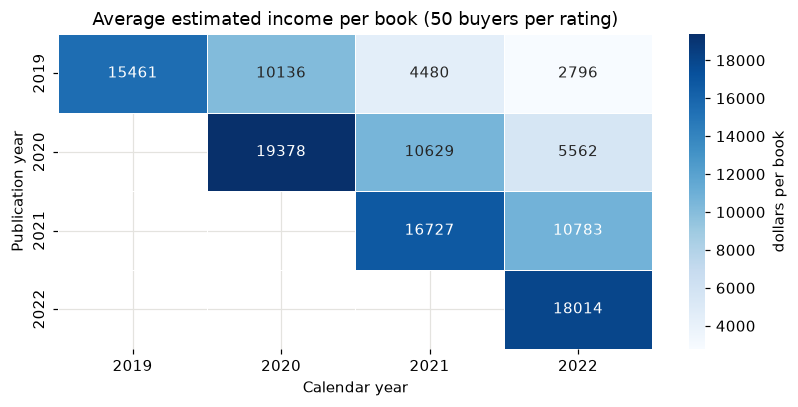

Books followed for three years: 19155


books   mean $  top 10% start at $  books with income %  % of year 1
group          year since publication                                                                      
publisher      1                       10503  29260.4             48687.9                 84.6        100.0
               2                       10503   8222.3             11363.9                 37.8         28.1
               3                       10503   4694.9              4820.8                 27.3         16.0
self-published 1                        8652  13791.2             29171.6                 86.8        100.0
               2                        8652   3678.5              3664.0                 27.0         26.7
               3                        8652   1946.0              1530.5                 17.7         14.1

In [43]:
paid_rated = books[books["price_known"] & (books["reviews_in_file"] > 0)].copy()
paid_rated["author_per_copy"] = np.where(paid_rated["self_published"] == 1,
                                         self_published_per_copy(paid_rated["price"], paid_rated["file_mb"]),
                                         paid_rated["price"] * PUBLISHER_SHARE)
paid_rated["published_day"] = pd.to_datetime(paid_rated["published"])
paid_rated["income_per_review"] = (paid_rated["ratings_per_review"] * paid_rated["author_per_copy"] * BUYERS_PER_RATING)

timeline = dated.merge(paid_rated[["parent_asin", "published_day", "income_per_review", "publisher_type"]], on="parent_asin")
timeline["year_of_life"] = (((timeline["day"] - timeline["published_day"]).dt.days / 365.25).clip(lower=0).astype(int) + 1)
timeline["income"] = timeline["income_per_review"]

followed = paid_rated[paid_rated["published_day"] + pd.Timedelta(days=round(3 * 365.25)) <= END_2022]
per_book = (timeline[timeline["parent_asin"].isin(followed["parent_asin"]) & timeline["year_of_life"].le(3)]
            .pivot_table(index="parent_asin", columns="year_of_life", values="income", aggfunc="sum")
            .reindex(followed["parent_asin"]).fillna(0))
per_book["publisher_type"] = followed.set_index("parent_asin")["publisher_type"]

life_rows = []
for group, part in per_book.groupby("publisher_type"):
    for year in [1, 2, 3]:
        life_rows.append({"group": group, "year since publication": year, "books": len(part), "mean $": part[year].mean(),
                          "top 10% start at $": part[year].quantile(0.9), "books with income %": (part[year] > 0).mean() * 100})
life = pd.DataFrame(life_rows).set_index(["group", "year since publication"])
life["% of year 1"] = life["mean $"] / life.groupby(level=0)["mean $"].transform("first") * 100

cohorts = paid_rated.assign(cohort=paid_rated["published_day"].dt.year).groupby("cohort").size()
timeline["cohort"] = timeline["published_day"].dt.year
calendar = timeline[timeline["year"].between(2019, 2022) & (timeline["year"] >= timeline["cohort"])].pivot_table(
    index="cohort", columns="year", values="income", aggfunc="sum").div(cohorts, axis=0)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.heatmap(calendar, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5, cbar_kws={"label": "dollars per book"}, ax=ax)
ax.set_xlabel("Calendar year")
ax.set_ylabel("Publication year")
ax.set_title("Average estimated income per book (50 buyers per rating)")
plt.tight_layout()
plt.show()
print("Books followed for three years:", len(followed))
life.round(1)

- **A book earns most in its first year.** A self-published book earns on average **13,791 dollars** in year 1, **3,679** in year 2
  (**26.7%** of year 1) and **1,946** in year 3 (**14.1%**).
- Books with a publisher follow the same pattern: **29,260**, **8,222** (28.1%) and **4,695** dollars (16.0%).
- The heatmap shows the same for every publication year. Books from 2019 average **15,461** dollars in 2019, **10,136** in 2020, **4,480** in
  2021 and **2,796** in 2022. The first cell of each row covers only the part of the year after publication.
- These are **averages pulled up by very successful books**, not the income of a typical book. Only 27.0% of the self-published books
  have a review in year 2, and most books have few reviews, so the years of a single book are uncertain.
- For the idea of passive income this is important: without new books or new promotion, income from one book falls quickly.

### 9.12 Groups by the number of ratings: 20, 50 and 100

I divide the books at **20, 50 and 100 estimated ratings up to the end of 2022** and compare the groups: how many books they hold, how many reviews stand behind
those ratings, what kind of books they are, and how much of the estimated income they bring.

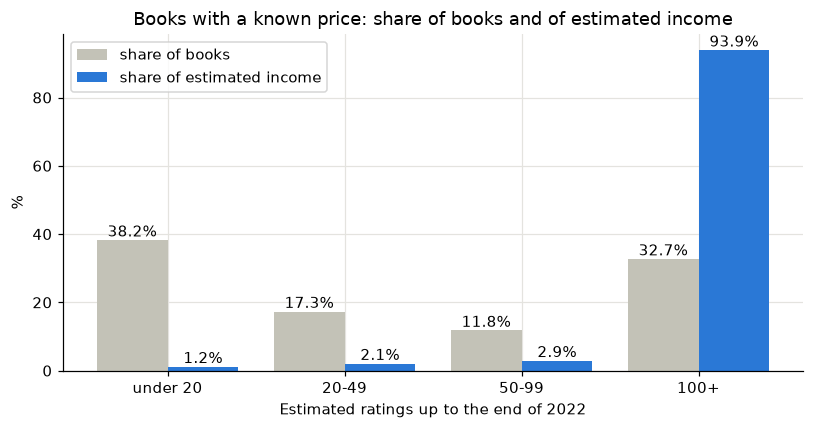

,books,median_ratings,median_reviews_in_file,ratings_per_review,self_published_pct,median_pages,books_%
rating_group,,,,,,,
under 20,21290,7.0,1.0,4.0,66.0,190.0,38.2
20-49,9642,31.0,2.0,12.5,50.2,221.0,17.3
50-99,6550,70.0,3.0,20.7,39.0,240.0,11.8
100+,18208,314.0,8.0,39.8,27.5,268.0,32.7


,paid_books,median_price,median_income,paid_books_%,income_%
rating_group,,,,,
under 20,21290,4.0,226.7,38.2,1.2
20-49,9642,5.0,1142.5,17.3,2.1
50-99,6550,5.0,2396.3,11.8,2.9
100+,18208,6.0,10911.3,32.7,93.9


In [44]:
RATING_LABELS = ["under 20", "20-49", "50-99", "100+"]
for table in [paid]:
    table["rating_group"] = pd.cut(table["ratings_to_2022"], [0, 20, 50, 100, np.inf], labels=RATING_LABELS, right=False)

group_table = paid.groupby("rating_group", observed=True).agg(
    books=("ratings_to_2022", "size"), median_ratings=("ratings_to_2022", "median"), median_reviews_in_file=("reviews_to_2022", "median"),
    ratings_per_review=("ratings_per_review", "median"), self_published_pct=("self_published", lambda s: s.mean() * 100),
    median_pages=("pages", "median"))
group_table["books_%"] = group_table["books"] / len(paid) * 100
paid_groups = paid.groupby("rating_group", observed=True).agg(paid_books=("price", "size"), median_price=("price", "median"),
                                                               median_income=("yearly_income", "median"), income=("yearly_income", "sum"))
paid_groups["paid_books_%"] = paid_groups["paid_books"] / paid_groups["paid_books"].sum() * 100
paid_groups["income_%"] = paid_groups["income"] / paid_groups["income"].sum() * 100

fig, ax = plt.subplots(figsize=(7.5, 4))
x = np.arange(len(paid_groups))
bars_books = ax.bar(x - 0.2, paid_groups["paid_books_%"], width=0.4, color=GREY, label="share of books")
bars_income = ax.bar(x + 0.2, paid_groups["income_%"], width=0.4, color=BLUE, label="share of estimated income")
ax.bar_label(bars_books, fmt="%.1f%%")
ax.bar_label(bars_income, fmt="%.1f%%")
ax.set_xticks(x, paid_groups.index)
ax.set_xlabel("Estimated ratings up to the end of 2022")
ax.set_ylabel("%")
ax.set_title("Books with a known price: share of books and of estimated income")
ax.legend()
plt.tight_layout()
plt.show()
display(group_table.round(1))
paid_groups.drop(columns="income").round(1)

- The groups are very unequal: **100+ ratings** is **32.7%** of the books with a known price and brings **93.9%** of the estimated
  income. The group **under 20** is 38.2% of the books and brings **1.2%**.
- The median estimated income rises from **227 dollars** (under 20) to **1,143** (20–49), **2,396** (50–99) and **10,911** (100+).
- Self-published books are **66.0%** of the lowest group and **27.5%** of the highest.
- The number of Amazon ratings per review in the file rises from **4** to **39.8**. So a review count from the file would not
  represent all groups equally.

### 9.13 What is a bestseller, and what does it tell us?

The Kaggle file marks a book with `isBestSeller`. Amazon's own help page on
[Sales Ranking](https://kdp.amazon.com/help/topic/G201648140) gives the rule for its rankings:

- ranks are based on **customer activity compared with other books**, so they are **relative**;
- recent activity counts more than older activity, and ranks are updated at least once a day;
- a book can be ranked in up to three Best Seller category lists, and each format has its own rank;
- the page gives **no number of copies and no sales limit** for becoming a bestseller.

I did not find an official description of the exact rule for the *Best Seller* label itself. Sellers' guides say that it goes
to the top product of a category, so a bestseller in a small category may sell far fewer copies than a book without the label
in a large one.

So the label can tell me **which** books sell well at a moment, but not **how many** copies they sell. I can only compare
labelled books with other books found in the same file, using the same estimate. For recent ratings I use the last complete
year, **2022**. The label itself was collected later, so it is not exactly from the same moment.

In [45]:
recent_reviews = dated.loc[dated["year"] == 2022, "parent_asin"].value_counts()
labelled = paid.merge(kaggle[["asin", "isBestSeller"]], left_on="parent_asin", right_on="asin")
labelled["recent_ratings"] = labelled["parent_asin"].map(recent_reviews).fillna(0) * labelled["ratings_per_review"].fillna(0)
labelled["group"] = np.where(labelled["isBestSeller"], "Best Seller label", "no label")

bestseller_table = labelled.groupby("group").agg(
    books=("price", "size"), median_price=("price", "median"), self_published_pct=("self_published", lambda s: s.mean() * 100),
    median_ratings=("ratings_to_2022", "median"), median_ratings_per_year=("ratings_per_year", "median"),
    mean_ratings_2022=("recent_ratings", "mean"), median_income=("yearly_income", "median"), mean_income=("yearly_income", "mean"))
copies = pd.DataFrame({f"copies a year, {b} buyers per rating": labelled.groupby("group")["ratings_per_year"].median() * b for b in SCENARIOS})
display(bestseller_table.round(1))
copies.round(0).astype(int)

,books,median_price,self_published_pct,median_ratings,median_ratings_per_year,mean_ratings_2022,median_income,mean_income
group,,,,,,,,
Best Seller label,27,10.4,18.5,633.0,399.4,504.7,44880.3,90201.7
no label,3931,10.0,19.8,402.0,173.7,464.1,20851.5,100093.9


,"copies a year, 20 buyers per rating","copies a year, 50 buyers per rating","copies a year, 100 buyers per rating"
group,,,
Best Seller label,7988,19971,39942
no label,3474,8685,17369


- Among books with a real price and at least one full year, only **27** of those found in the Kaggle file have the label, and **3,931**
  do not. **27 books are too few for firm conclusions.**
- The labelled books have about **399** ratings per year at the median, against **174** for the others.
- With my assumptions a median labelled book sells about **19,971 copies a year** (7,988 to 39,942 in the scenarios). This number comes from
  ratings and the assumption, so it **cannot be used to check the assumption**.
- **Answer to the question:** the label tells me that a book sold well compared with others at a moment. Amazon gives no sales limit,
  so bestsellers do not give me the number of copies sold.

### 9.14 Yearly income by price

Is a higher price better for the author, or does a larger share at a lower price win? I use books with a known price and 50
buyers per rating, and I show the **median** book, because a few very successful books pull the mean far up.

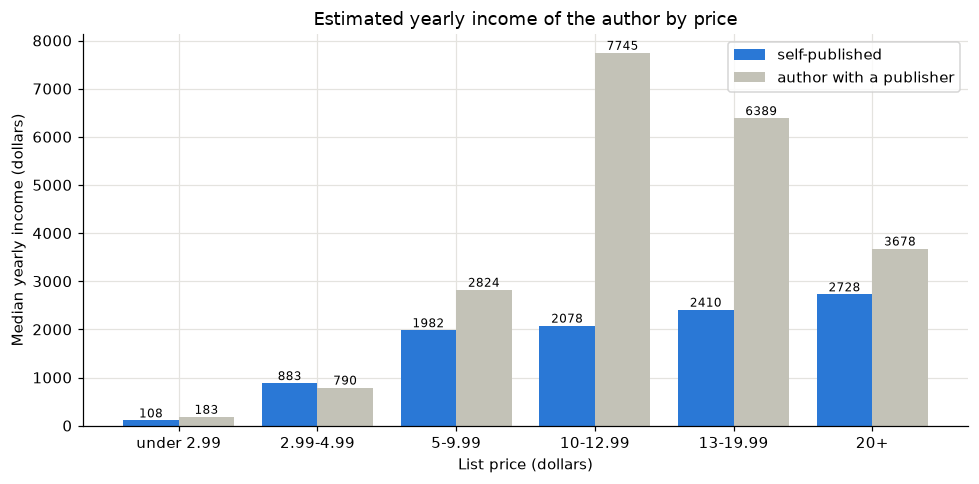

books  median_ratings_per_year  median_author_dollars  median_income  mean_income
publisher_type price_group                                                                                   
publisher      under 2.99    2393                     16.3                    0.2          183.3       2878.2
               2.99-4.99    10083                     22.5                    0.7          790.2       4575.4
               5-9.99       10004                     39.3                    1.4         2823.8      18387.9
               10-12.99      2927                     74.0                    2.1         7745.0      54356.3
               13-19.99      2584                     46.1                    2.6         6388.5      60706.5
               20+           1243                     13.1                    5.2         3678.4      16820.2
self-published under 2.99    3526                      5.1                    0.3          108.4       1267.0
               2.99-4.99    14779                      7.9                    2.3          883.0       6699.4
               5-9.99        7228                      7.8                    5.2         1982.1      13342.7
               10-12.99       259                      9.8                    4.2         2078.3      11578.6
               13-19.99       389                      8.8                    5.6         2410.1      12488.5
               20+            275                      4.3                   10.5         2728.5      17494.8

In [46]:
price_income = paid.groupby(["publisher_type", "price_group"], observed=True).agg(
    books=("price", "size"), median_ratings_per_year=("ratings_per_year", "median"),
    median_author_dollars=("author_per_copy", "median"), median_income=("yearly_income", "median"), mean_income=("yearly_income", "mean"))

chart = price_income["median_income"].unstack(0)
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(chart))
bars_self = ax.bar(x - 0.2, chart["self-published"], width=0.4, color=BLUE, label="self-published")
bars_publisher = ax.bar(x + 0.2, chart["publisher"], width=0.4, color=GREY, label="author with a publisher")
ax.bar_label(bars_self, fmt="%.0f", fontsize=8)
ax.bar_label(bars_publisher, fmt="%.0f", fontsize=8)
ax.set_xticks(x, chart.index)
ax.set_xlabel("List price (dollars)")
ax.set_ylabel("Median yearly income (dollars)")
ax.set_title("Estimated yearly income of the author by price")
ax.legend()
plt.tight_layout()
plt.show()
price_income.round(1)

- **Under 2.99 dollars** is the weakest group for both routes: a median of **108 dollars** for self-published books.
- For self-published books, **2.99–4.99** and **5–9.99 dollars** have almost the same ratings per year (7.9 and 7.8), but the author receives
  more per copy (2.3 and 5.2 dollars). The median income rises from **883** to **1,982 dollars**.
- At **2.99–4.99 dollars** the self-published author earns a little **more** than the author with a publisher (883 against 790 dollars),
  although publisher books have many more ratings per year (22.5 against 7.9).
- From 5 dollars upward the publisher route is ahead, most at **10–12.99 dollars** (7,745 against 2,078 dollars).
- Above 9.99 dollars there are few self-published books (259, 389 and 275), so those results are less certain.

### 9.15 Yearly income by niche and price

First I compare the niches for both routes (at least 200 books with a known price in each route). Then a **heatmap** shows the
median income of **self-published** books by niche and price group. An empty cell means fewer than 30 books.

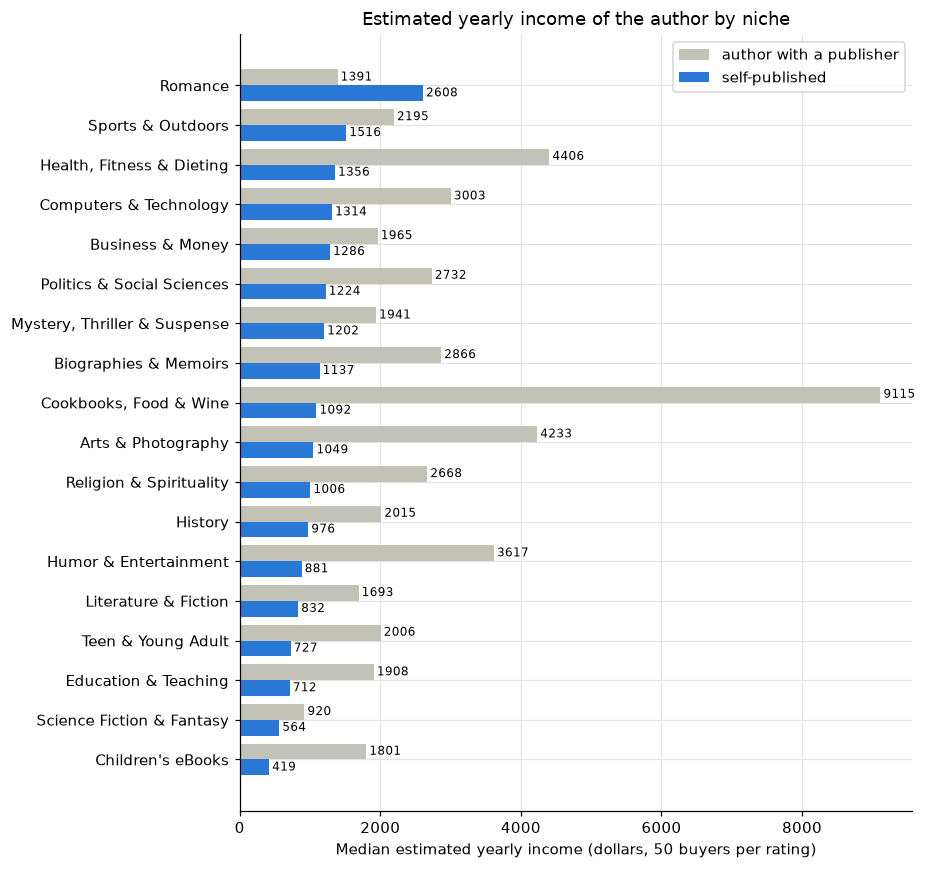

,books_publisher,books_self,median_publisher,median_self
niche,,,,
Romance,2996,2959,1391,2608
Sports & Outdoors,216,299,2195,1516
"Health, Fitness & Dieting",295,459,4406,1356
Computers & Technology,486,271,3003,1314
Business & Money,1327,1443,1965,1286
Politics & Social Sciences,872,371,2732,1224
"Mystery, Thriller & Suspense",1913,1311,1941,1202
Biographies & Memoirs,899,949,2866,1137
"Cookbooks, Food & Wine",413,238,9115,1092


In [47]:
niche_income = paid.pivot_table(index="niche", columns="publisher_type", values="yearly_income", aggfunc=["size", "median"])
niche_income.columns = ["books_publisher", "books_self", "median_publisher", "median_self"]
niche_income = niche_income[(niche_income["books_publisher"] >= 200) & (niche_income["books_self"] >= 200)]
niche_income = niche_income.sort_values("median_self")

fig, ax = plt.subplots(figsize=(8.5, 8))
y = np.arange(len(niche_income))
bars_publisher = ax.barh(y + 0.2, niche_income["median_publisher"], height=0.4, color=GREY, label="author with a publisher")
bars_self = ax.barh(y - 0.2, niche_income["median_self"], height=0.4, color=BLUE, label="self-published")
ax.bar_label(bars_publisher, fmt="%.0f", padding=2, fontsize=8)
ax.bar_label(bars_self, fmt="%.0f", padding=2, fontsize=8)
ax.set_yticks(y, niche_income.index)
ax.set_xlabel("Median estimated yearly income (dollars, 50 buyers per rating)")
ax.set_title("Estimated yearly income of the author by niche")
ax.legend()
plt.tight_layout()
plt.show()
niche_income.sort_values("median_self", ascending=False).round(0).astype(int)

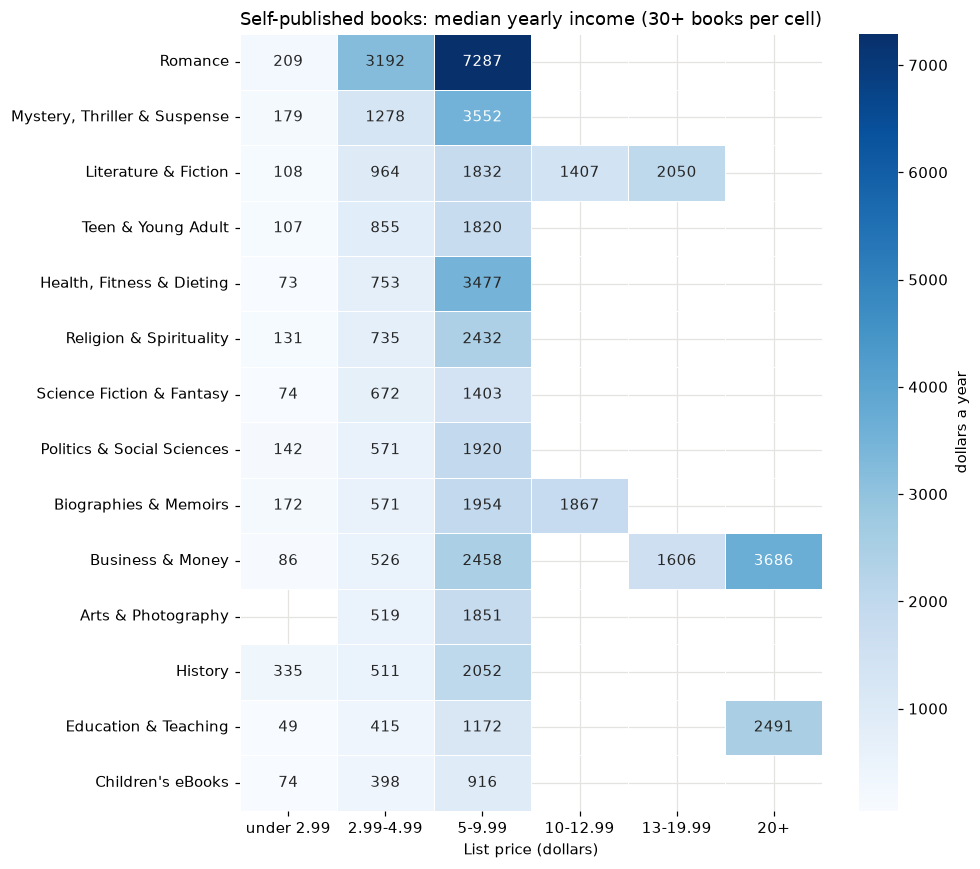

In [48]:
self_paid = paid[paid["self_published"] == 1]
keep_niches = self_paid["niche"].value_counts().loc[lambda s: s >= 300].index
heat = self_paid[self_paid["niche"].isin(keep_niches)].pivot_table(
    index="niche", columns="price_group", values="yearly_income", aggfunc=["median", "size"], observed=True)
heat_values = heat["median"].where(heat["size"] >= 30)
heat_values = heat_values.loc[heat_values["2.99-4.99"].sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(heat_values, annot=True, fmt=".0f", cmap="Blues", linewidths=0.5, cbar_kws={"label": "dollars a year"}, ax=ax)
ax.set_xlabel("List price (dollars)")
ax.set_ylabel("")
ax.set_title("Self-published books: median yearly income (30+ books per cell)")
plt.tight_layout()
plt.show()

- **Romance** is the only niche in the table where the median self-published book earns more than the median publisher book (**2,608**
  against **1,391 dollars**).
- Next for self-published books are **Sports & Outdoors** (1,516), **Health, Fitness & Dieting** (1,356) and **Computers & Technology** (1,314).
- The weakest are **Children's eBooks** (419), **Science Fiction & Fantasy** (564) and **Education & Teaching** (712).
- The largest difference in favour of a publisher is in **Cookbooks, Food & Wine** (9,115 against 1,092 dollars).
- In the heatmap **5–9.99 dollars** is above 2.99–4.99 dollars in **every** niche, and the highest cell is **Romance at 5–9.99 dollars
  (7,287)**. Books at different prices can also differ in length and audience, so this does not prove that a higher price causes
  a higher income.

### 9.16 What the data can and cannot give

| Need | What I can do with the data I have | How sure |
|---|---|---|
| **Price** | the real list price for 40% of the books; the other books are left out of income | reliable, but it is the price of 2023 |
| **Copies sold** | ratings × an assumed number of buyers per rating (9.10) | only a scenario |
| **Income by year** | dated reviews up to 2022 scaled to Amazon's total ratings (9.9, 9.11) | shows the pattern better than the amount |
| **Bestsellers** | which books have the label (9.13) | shows a label, not sales numbers |

**Dummy variables.** They are not needed for this exploration. Groups are enough for tables and charts, and the models make
dummy variables themselves with `OneHotEncoder`.

**Synthetic data.** I do not create synthetic sales. They would come only from my assumptions, and could then look like evidence.
The three scenarios show the same uncertainty openly.

**Limits of the income estimate**

- **There are no real sales or income in the data.** The dollar amounts are estimates, and the buyers-per-rating number is an
  assumption, the same for all niches, although readers of different niches may rate books more or less often.
- **Ratings may be shared between the formats of a book.** A publisher book with a print edition can collect ratings from print
  readers too, so its e-book income is probably **overestimated**.
- **Kindle Unlimited income is not measured.** Books with price 0 are left out, and page-read payments are not in the data.
- **Books without any rating are not in the data**, so typical income is overestimated.
- **The split of ratings by year is estimated.** Reviews stand in for ratings, and the incomplete 2023 can make the part I place up
  to 2022 a little too large.
- **The price is from 2023**, the only price I have, and I treat it as the price of 2019–2022.
- **Costs are not counted**: editing, a cover and advertising for self-published authors. An advance from a publisher is not
  counted either.
- These are **associations, not causes**.

### 9.17 What do ratings tell us?

Copies sold are not in the data, so ratings are my measure of **popularity**: how many readers reacted to a book. A fair
comparison needs the **same time for every book**, because a book from 2019 had longer to collect ratings than a book from 2021.
So I estimate each book's **ratings in its first 12 months**:

`first_year_ratings` = reviews in the first 12 months × the book's `ratings_per_review` (9.9).

I use books published up to 2021, because their first 12 months ended by 2022. I also take `average_rating` (the stars) from the
original file, only to describe the books. It is not a feature, because it is known only after readers have rated the book.

In [49]:
stars = (raw.select("parent_asin", "average_rating").filter(pl.col("parent_asin").is_in(books["parent_asin"].to_list()))
         .collect(engine="streaming").to_pandas().set_index("parent_asin")["average_rating"])

popularity = books[books["full_year"] & (books["reviews_in_file"] > 0)].copy()
popularity["published_day"] = pd.to_datetime(popularity["published"])
first_days = dated.merge(popularity[["parent_asin", "published_day"]], on="parent_asin")
first_days = first_days[(first_days["day"] - first_days["published_day"]).dt.days < 365]
popularity["first_year_reviews"] = popularity["parent_asin"].map(first_days["parent_asin"].value_counts()).fillna(0)
popularity["first_year_ratings"] = popularity["first_year_reviews"] * popularity["ratings_per_review"]
popularity["stars"] = popularity["parent_asin"].map(stars)

ordered = popularity["first_year_ratings"].sort_values(ascending=False)
concentration = pd.DataFrame({"top share of books %": [1, 10, 25, 50]})
concentration["share of first-year ratings %"] = [ordered.head(round(len(ordered) * p / 100)).sum() / ordered.sum() * 100
                                                  for p in concentration["top share of books %"]]
star_groups = pd.cut(popularity["rating_number"], [0, 19, 49, 99, 499, np.inf], labels=["1-19", "20-49", "50-99", "100-499", "500+"])
star_table = popularity.groupby(star_groups, observed=True)["stars"].agg(books="size", mean_stars="mean", median_stars="median")

print(f"Books: {len(popularity):,} | median first-year ratings: {popularity['first_year_ratings'].median():.0f}")
print("By publication year (median first-year ratings):",
      popularity.groupby("publication_year")["first_year_ratings"].median().round(0).to_dict())
print("First-year ratings, percentiles:",
      popularity["first_year_ratings"].quantile([0.25, 0.5, 0.75, 0.9]).round(0).to_dict())
print(f"Spearman correlation between stars and the number of ratings: {popularity['stars'].corr(popularity['rating_number'], method='spearman'):.2f}")
display(concentration.round(1))
star_table.round(2)

Books: 135,839 | median first-year ratings: 33
By publication year (median first-year ratings): {2019: 31.0, 2020: 32.0, 2021: 35.0}
First-year ratings, percentiles: {0.25: 7.0, 0.5: 33.0, 0.75: 165.0, 0.9: 561.0}
Spearman correlation between stars and the number of ratings: -0.12


,top share of books %,share of first-year ratings %
0,1,33.0
1,10,73.8
2,25,90.9
3,50,98.2


,books,mean_stars,median_stars
rating_number,,,
1-19,46762,4.44,4.6
20-49,22946,4.39,4.4
50-99,15743,4.39,4.4
100-499,31634,4.43,4.5
500+,18754,4.47,4.5


- **Ratings show how many readers reacted, and this is very uneven.** The median book has **33** first-year ratings, a quarter of the books
  have 7 or fewer, a quarter **165 or more**, and the top 10% start at **561**.
- The **top 1%** of the books hold **33.0%** of all first-year ratings, the top 10% hold **73.8%** and the top 25% hold **90.9%**.
- The first-year measure is fair across years: the median is **31**, **32** and **35** for books from 2019, 2020 and 2021.
- **Stars do not show popularity.** The average is about **4.4–4.5** in every group, and the correlation with the number of ratings is only
  **−0.12**. So I measure popularity by the number of ratings, not by stars.
- Ratings do **not** show copies sold. They show reader response, which is what this target measures.

### 9.18 Which number should define a popular book?

How should the number be chosen? I test several thresholds for `first_year_ratings`, and I write the rules **before**
looking for the winner. The limits are my judgment, chosen to make the target useful for a new author:

| Rule | Limit | Why |
|---|---|---|
| Popular books are neither rare nor ordinary | 20–40% of the books | popularity should mean more than average, and the models need enough examples |
| The group holds most reader response | at least 90% of first-year ratings | the threshold should separate the books that really collect ratings |
| It is fair across publication years | difference of at most 3 points | the result should not depend on the year |
| It can be predicted about as well as the best threshold | ROC AUC at most 0.01 below the best | it should suit the prediction question |
| New authors can still reach it | at least 10% of first books | the question is also about new authors |

For prediction I use a simple logistic regression with what is known about a **book draft and its author**: niche, pages, title
words, series, self-published and earlier books. Price is left out for now. `GroupKFold` keeps all books of an author in the
same fold, so the model is always tested on authors it has not seen.

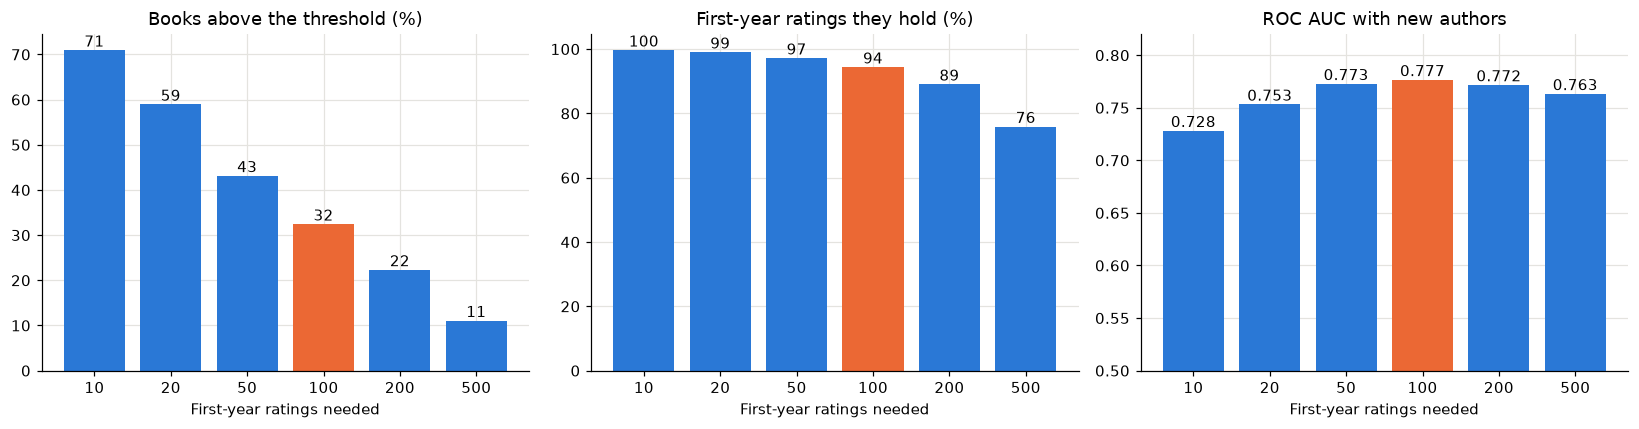

,popular_books,popular_%,ratings_held_%,year_gap_points,roc_auc,first_books_%,self_published_%,passes_all_rules
threshold,,,,,,,,
10,96367,70.942,99.656,4.755,0.728,55.333,65.395,False
20,80068,58.943,99.039,3.623,0.753,38.684,51.344,False
50,58592,43.133,97.183,1.916,0.773,21.617,34.870,False
100,44036,32.418,94.378,1.721,0.777,13.220,25.050,True
200,30313,22.315,89.065,1.546,0.772,7.767,16.466,False
500,15035,11.068,75.904,1.145,0.763,3.574,7.505,False


In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

popularity["log_earlier_books"] = np.log1p(popularity["author_earlier_books"])
draft_numeric = ["pages", "title_words", "is_series", "self_published", "log_earlier_books"]
draft_features = draft_numeric + ["niche"]
prepare = ColumnTransformer([
    ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), draft_numeric),
    ("niche", OneHotEncoder(handle_unknown="ignore"), ["niche"]),
])
author_groups = popularity["author"].fillna(popularity["parent_asin"])

rows = []
for threshold in [10, 20, 50, 100, 200, 500]:
    target = (popularity["first_year_ratings"] >= threshold).astype(int)
    by_year = target.groupby(popularity["publication_year"]).mean() * 100
    auc = cross_val_score(make_pipeline(prepare, LogisticRegression(max_iter=300)), popularity[draft_features], target,
                          groups=author_groups, cv=GroupKFold(5), scoring="roc_auc").mean()
    rows.append({"threshold": threshold, "popular_books": target.sum(), "popular_%": target.mean() * 100,
                 "ratings_held_%": popularity.loc[target == 1, "first_year_ratings"].sum() / popularity["first_year_ratings"].sum() * 100,
                 "year_gap_points": by_year.max() - by_year.min(), "roc_auc": auc,
                 "first_books_%": target[popularity["author_earlier_books"] == 0].mean() * 100,
                 "self_published_%": target[popularity["self_published"] == 1].mean() * 100})
thresholds = pd.DataFrame(rows).set_index("threshold")
thresholds["passes_all_rules"] = (thresholds["popular_%"].between(20, 40) & (thresholds["ratings_held_%"] >= 90)
                                  & (thresholds["year_gap_points"] <= 3) & (thresholds["roc_auc"] >= thresholds["roc_auc"].max() - 0.01)
                                  & (thresholds["first_books_%"] >= 10))

labels = thresholds.index.astype(str)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title, fmt in [(axes[0], "popular_%", "Books above the threshold (%)", "%.0f"),
                               (axes[1], "ratings_held_%", "First-year ratings they hold (%)", "%.0f"),
                               (axes[2], "roc_auc", "ROC AUC with new authors", "%.3f")]:
    colors = [ORANGE if passed else BLUE for passed in thresholds["passes_all_rules"]]
    bars = ax.bar(labels, thresholds[column], color=colors)
    ax.bar_label(bars, fmt=fmt)
    ax.set_xlabel("First-year ratings needed")
    ax.set_title(title)
axes[2].set_ylim(0.5, 0.82)
plt.tight_layout()
plt.show()
thresholds.round(3)

- **100 first-year ratings is the only threshold that passes all five rules.**
- **10, 20 and 50** are too easy: **71%**, **59%** and **43%** of the books would count as popular.
- **200** is close, but its books hold 89.1% of the ratings and only 7.8% of first books reach it. **500** is reached by only 11.1% of the books
  and 3.6% of first books.
- At 100, **32.4%** of the books are popular, roughly the top third. They hold **94.4%** of the first-year ratings, the years differ by only
  **1.7 points**, and **13.2%** of first books and **25.0%** of self-published books reach it.
- The ROC AUC is highest at 100 (**0.777**), but 50 and 200 are close (0.773 and 0.772). So prediction alone does not decide the number; the
  other rules do. The limits are my judgment, and this table shows what would change with another choice.

**Rule.** A book is **popular** if it has at least **100 estimated ratings in its first 12 months**
(`popular_first_year` = 1). I compare this new definition with the old one, 100 ratings in total.

In [51]:
POPULAR_THRESHOLD = 100
popularity["popular_first_year"] = (popularity["first_year_ratings"] >= POPULAR_THRESHOLD).astype(int)
print(f"Popular books: {popularity['popular_first_year'].sum():,} of {len(popularity):,} ({popularity['popular_first_year'].mean():.1%})")
print(f"Median reviews in the first year of books with 100-199 estimated ratings: "
      f"{popularity.loc[popularity['first_year_ratings'].between(100, 199.999), 'first_year_reviews'].median():.0f}")
pd.crosstab(popularity["popular"].map({0: "under 100 in total", 1: "100+ in total"}),
            popularity["popular_first_year"].map({0: "not popular in year 1", 1: "popular in year 1"}))

Popular books: 44,036 of 135,839 (32.4%)
Median reviews in the first year of books with 100-199 estimated ratings: 7


popular_first_year,not popular in year 1,popular in year 1
popular,,
100+ in total,6352,44036
under 100 in total,85451,0


- **44,036** of the 135,839 books (**32.4%**) are popular by the new definition.
- All of them also have at least 100 ratings in total. Another **6,352** books have 100+ in total but reach it only after their first year, so
  the new definition no longer rewards extra time.
- The estimate is not exact: books with 100–199 estimated ratings have a median of only **7** reviews in their first year. Books close to the
  threshold can therefore fall on the wrong side.

### 9.19 What are popular books like?

Now I compare popular books with the others, using only what is known about a draft and its author. The stars are shown only for
description.

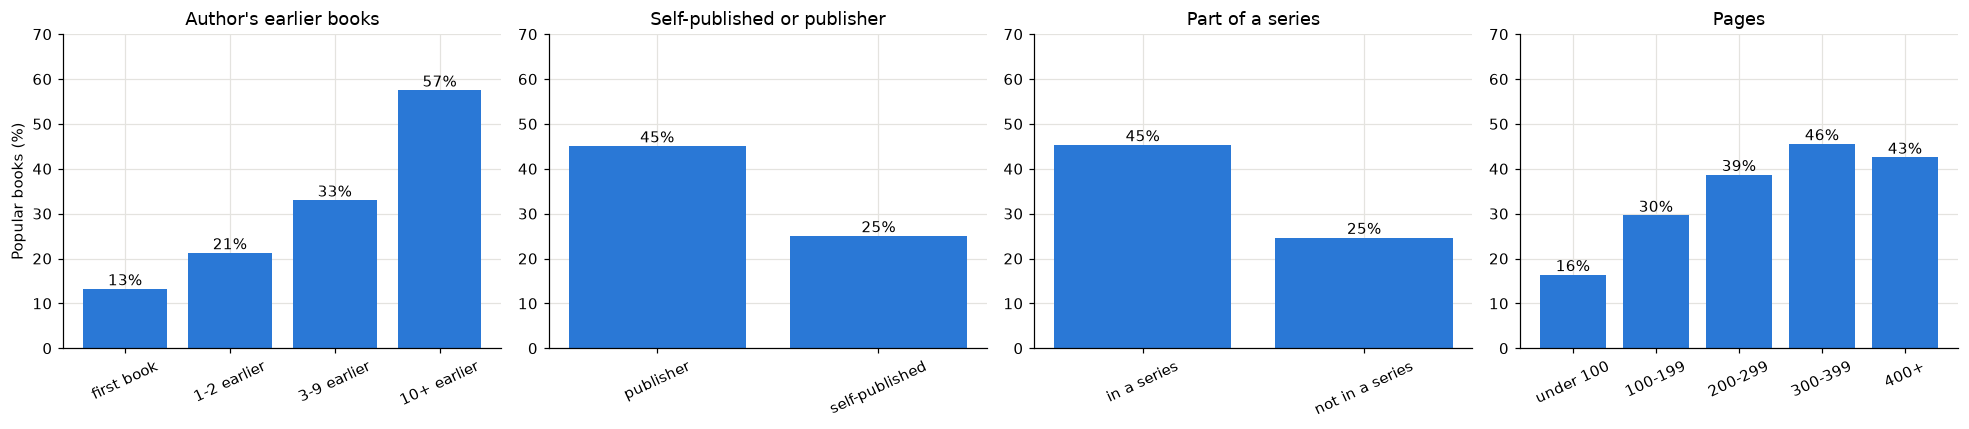

popular_first_year,not popular,popular
books,91803.0,44036.0
median_pages,191.0,256.0
median_title_words,8.0,9.0
series_pct,30.3,52.4
self_published_pct,70.1,48.8
median_earlier_books,1.0,12.0
first_book_pct,39.5,12.5
mean_stars,4.4,4.4


,books,popular_pct
niche,,
Romance,15833,47.7
"Mystery, Thriller & Suspense",8339,41.7
Religion & Spirituality,7772,37.4
Literature & Fiction,50551,36.9
Humor & Entertainment,1163,33.4
Engineering & Transportation,362,11.6
Computers & Technology,1289,11.2
Self-Help,398,10.1
Education & Teaching,1912,9.3


In [52]:
profile = popularity.groupby("popular_first_year").agg(
    books=("pages", "size"), median_pages=("pages", "median"), median_title_words=("title_words", "median"),
    series_pct=("is_series", lambda s: s.mean() * 100), self_published_pct=("self_published", lambda s: s.mean() * 100),
    median_earlier_books=("author_earlier_books", "median"), first_book_pct=("author_earlier_books", lambda s: (s == 0).mean() * 100),
    mean_stars=("stars", "mean")).rename(index={0: "not popular", 1: "popular"}).T

popularity["series_label"] = popularity["is_series"].map({0: "not in a series", 1: "in a series"})
popularity["pages_group"] = pd.cut(popularity["pages"], [0, 99, 199, 299, 399, np.inf], labels=["under 100", "100-199", "200-299", "300-399", "400+"])
panels = [("author_experience", "Author's earlier books"), ("publisher_type", "Self-published or publisher"),
          ("series_label", "Part of a series"), ("pages_group", "Pages")]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (column, title) in zip(axes, panels):
    share = popularity.groupby(column, observed=True)["popular_first_year"].mean() * 100
    bars = ax.bar(share.index.astype(str), share.values, color=BLUE)
    ax.bar_label(bars, fmt="%.0f%%")
    ax.set_title(title)
    ax.set_ylim(0, 70)
    ax.tick_params(axis="x", rotation=25)
axes[0].set_ylabel("Popular books (%)")
plt.tight_layout()
plt.show()

niches = popularity.groupby("niche")["popular_first_year"].agg(books="size", popular_pct=lambda s: s.mean() * 100)
niches = niches[niches["books"] >= 200].sort_values("popular_pct", ascending=False)
display(profile.round(1))
pd.concat([niches.head(5), niches.tail(5)]).round(1)

- **Author's experience** shows the strongest difference: **13%** of first books are popular, against **57%** of books by authors with 10+ earlier books.
  The median popular book has an author with **12** earlier books, against **1** for the others.
- **Series:** **45%** of books in a series are popular, against 25% of the others.
- **Publisher:** **45%** of publisher books are popular, against **25%** of self-published books.
- **Length:** the share rises from **16%** under 100 pages to **46%** at 300–399 pages, and is 43% at 400 or more.
- **Niche:** **Romance** (47.7%) and **Mystery, Thriller & Suspense** (41.7%) lead. **Nonfiction** (5.2%) and **Education & Teaching** (9.3%) are lowest.
- **Stars** are the same in both groups (about **4.4**), so a high rating does not separate popular books.
- These are associations: for example, experienced authors may already have an audience.

## 10. Key findings

| Finding | What it means |
|---|---|
| **36%** of new Kindle books (2019–2022) have 100 ratings in total. | This was the first working target; 9.18 makes it fair in time. |
| An author's **earlier books** are the strongest sign: 16% for a first book, 61% with 10+ earlier books. | Experience and an existing audience matter most. |
| **Publisher** books reach 100 ratings much more often than **self-published** books (50% against 28%), in every niche. | Publishers' marketing helps; self-publishers should be compared with self-publishers. |
| **Series** books reach 100 ratings more often (49% against 29%). | Writing a series is a decision that helps. |
| **Romance** (50%) and **Mystery, Thriller & Suspense** (46%) are the strongest niches; Education, Self-Help, Computers, Business and Children's eBooks the weakest (12–17%). | The niche changes the chance from about 1 in 10 to 1 in 2. |
| For self-published books the gap to publishers is smallest in **Romance** (47% against 55%). | Romance is the most open niche for self-publishers. |
| **A price of 0 is mostly Kindle Unlimited** (97.5% of the checked books). | Income is estimated only for books with a real list price. |
| The data has **no sales**, and the Best Seller label has no published sales limit. | Copies sold remain an assumption (20, 50 or 100 buyers per rating). |
| 2023 is incomplete, so yearly results stop at **31 December 2022**. | Only complete years are compared. |
| Self-published authors keep most at **2.99–9.99 dollars** (about 64–66%); an assumed publisher contract gives 17.5%. | Price changes the author's share. |
| The median self-published book earns about **920 dollars a year** with 50 buyers per rating (368–1,840 in the scenarios). | Income can be studied only as an estimate. |
| Income falls fast: year 2 is **26.7%** and year 3 **14.1%** of year 1 for self-published books. | One book is not a steady passive income. |
| Books with **100+ ratings** are 32.7% of the priced books and bring **93.9%** of the estimated income. | Income is very concentrated. |
| A popular book is defined as **100+ estimated ratings in the first 12 months**: 32.4% of the books, holding 94.4% of first-year ratings. | The number is chosen by clear rules and is fair across publication years. |
| Popular books more often come from experienced authors (57% with 10+ earlier books, 13% for first books) and series (45% against 25%). Stars do not separate them. | Author experience and series are the clearest signs. |
| **Romance** is the best self-published niche (2,608 dollars), and 5–9.99 dollars is stronger than 2.99–4.99 dollars in every niche. | These are the clearest leads for the question. |

## 11. Decisions carried forward

**Main question**

> *Can we predict, from the characteristics of a book draft, whether a new Kindle book will reach at least 100 ratings in its first
> 12 months on Amazon?*

- **Target:** `popular_first_year` (1 = at least 100 estimated ratings in the first 12 months, chosen in 9.18).
- **Books:** the 135,839 books published from 2019 to 2021 that have at least one review in the file.
- **Features:** `niche`, `pages`, `title_words`, `is_series`, `self_published` and `author_earlier_books`.
- **Not used in the models:** `price`, because I leave it for a possible later step; `publication_year`, because a future book has no
  past year; ratings, reviews and stars, because they exist only after publication.
- **Models** (one per notebook): logistic regression, random forest and gradient boosting, each compared with a baseline that always
  predicts the most common answer, and a final comparison notebook.
- **Split:** 80% training and 20% test books, with all books of an author on the same side, so the test shows authors the model has
  not seen.
- **Measures:** ROC AUC, accuracy, precision, recall, F1 and the confusion matrix.

## 12. Export

I save one row per book with the final target, the features and a few columns for checking the results in `data/processed/`.

In [53]:
model_columns = ["parent_asin", "title", "author", "niche", "pages", "title_words", "is_series", "self_published",
                 "author_earlier_books", "publication_year", "price", "rating_number", "first_year_reviews",
                 "first_year_ratings", "popular_first_year"]
model_table = popularity[model_columns]
PROCESSED.mkdir(parents=True, exist_ok=True)
output_file = PROCESSED / "kindle_books_popularity.parquet"
model_table.to_parquet(output_file, index=False)
print("Saved:", output_file.relative_to(PROJECT), model_table.shape)
print(f"Popular books: {model_table['popular_first_year'].mean():.1%}")

Saved: data\processed\kindle_books_popularity.parquet (135839, 15)
Popular books: 32.4%


## 13. Appendix

Not used.